## Описание задачи

Требуется самостоятельно пройти все шесть блоков анализа трафика для pcap файла Friday-WorkingHours.pcap и подготовить отчёт в виде Jupyter Notebook.
При этом требуется выполнить следующие модификации анализа:
1. Доработать код анализа потоков, чтобы корректно определялся инициатор соединения (для протокола TCP – тот, кто направил SYN пакет, для прочих протоколов – тот, кто первый направил пакет).
2. Добавить новый признак – внешний или внутренний адрес и использовать этот признак в ходе анализа.
3. Доработать метод выявления маршрутизаторов (учесть, что трафик может собираться в разных сегментах по разные стороны от маршрутизатора).
4. Привести интерпретацию результатов анализа для каждой статистики (если она выдает какой-то результат).

---

## Решение

In [4]:
# Импортируем необходимые библиотеки для анализа сетевого трафика и обработки данных
from scapy.all import PcapReader, IP, TCP, UDP
import pandas as pd
import ipaddress
import matplotlib.pyplot as plt

print("Библиотеки успешно импортированы")

Библиотеки успешно импортированы


In [2]:
# Создаем пустой список для накопления данных
data = []
print("Начинаем чтение 9 ГБ файла.")

# Используем PcapReader для потокового чтения, чтобы не перегружать оперативную память
with PcapReader('Friday-WorkingHours.pcap') as pcap_reader:
    for i, pkt in enumerate(pcap_reader):
        # Рассматриваем только пакеты, содержащие IP-слой
        if IP in pkt:
            proto = "Other"
            sport, dport, flags = 0, 0, ""
            
            # Извлекаем протокол, порты и TCP-флаги (необходимы для определения инициатора)
            if TCP in pkt:
                proto = "TCP"
                sport, dport = pkt[TCP].sport, pkt[TCP].dport
                flags = str(pkt[TCP].flags)
            elif UDP in pkt:
                proto = "UDP"
                sport, dport = pkt[UDP].sport, pkt[UDP].dport
            elif pkt[IP].proto == 1:
                proto = "ICMP"
            
            # Сохраняем данные в виде кортежа для экономии памяти
            data.append((
                float(pkt.time), pkt[IP].src, pkt[IP].dst, proto, len(pkt),
                pkt.src, pkt.dst, sport, dport, flags
            ))
            
        # Выводим прогресс каждые 500 000 пакетов
        if i % 500000 == 0 and i > 0:
            print(f"Обработано {i} пакетов...")

# Формируем DataFrame с необходимыми столбцами
df = pd.DataFrame(data, columns=[
    'time', 'src_ip', 'dst_ip', 'protocol', 'length', 
    'src_mac', 'dst_mac', 'sport', 'dport', 'flags'
])

# Сохраняем результат в pickle, чтобы избежать повторного долгого чтения
df.to_pickle('traffic_data_full.pkl')
print(f"ГОТОВО! Данные сохранены в traffic_data_full.pkl. Строк: {len(df)}")
df.head()

Начинаем чтение 9 ГБ файла.
Обработано 500000 пакетов...


KeyboardInterrupt: 

Был загружен файл трафика Friday-WorkingHours.pcap объемом 9 ГБ. Для экономии оперативной памяти использовался потоковый метод чтения PcapReader. Всего успешно обработано и загружено в DataFrame 9 915 680 пакетов. Данные сохранены в формате pickle для ускорения повторных запусков и защиты от потери результатов при сбоях.


#### Детализированный лог пакетов (из таблицы данных):

| № | time | src_ip | dst_ip | protocol | length | src_mac | dst_mac | sport | dport | flags |
| :-: | :--- | :--- | :--- | :---: | :-: | :--- | :--- | :-: | :-: | :-: |
| **0** | 1.499429e+09 | 192.168.10.50 | 192.168.10.3 | TCP | 469 | 00:19:b9:0a:69:f1 | 18:66:da:9b:e3:7d | 56108 | 3268 | PA |
| **1** | 1.499429e+09 | 192.168.10.50 | 192.168.10.3 | TCP | 469 | 00:19:b9:0a:69:f1 | 18:66:da:9b:e3:7d | 56108 | 3268 | PA |
| **2** | 1.499429e+09 | 192.168.10.3 | 192.168.10.50 | TCP | 138 | 18:66:da:9b:e3:7d | 00:19:b9:0a:69:f1 | 3268 | 56108 | PA |
| **3** | 1.499429e+09 | 192.168.10.3 | 192.168.10.50 | TCP | 138 | 18:66:da:9b:e3:7d | 00:19:b9:0a:69:f1 | 3268 | 56108 | PA |
| **4** | 1.499429e+09 | 192.168.10.50 | 192.168.10.3 | TCP | 66 | 00:19:b9:0a:69:f1 | 18:66:da:9b:e3:7d | 56108 | 3268 | A |


---
## Блок 1. Общая статистика

In [5]:
# Загружаем сохраненные данные
df = pd.read_pickle('traffic_data_full.pkl')

# Рассчитываем общее количество пакетов, их суммарный объем и длительность захвата
total_packets = len(df)
total_bytes = df['length'].sum()
duration = df['time'].max() - df['time'].min()

# Переводим байты в гигабайты, а секунды в часы для удобства восприятия
print(f"Всего пакетов: {total_packets:,}")
print(f"Общий объем: {total_bytes / (1024**3):.2f} ГБ")
print(f"Длительность захвата: {duration / 3600:.2f} часов")

Всего пакетов: 9,915,680
Общий объем: 7.91 ГБ
Длительность захвата: 8.05 часов


В ходе анализа установлено, что зафиксировано 9 915 680 пакетов. Общий объем переданных данных составляет 7.91 ГБ, а длительность захвата - 8.05 часов. Полученные данные представляют собой репрезентативную выборку для анализа поведения рабочей станции в течение полного рабочего дня. Соотношение объема и количества пакетов указывает на смешанный характер трафика, включающий как объемные передачи данных, так и большое количество служебных пакетов.

---
## Блок 2. Распределение по протоколам и анализ направлений (Модификация 2)

In [ ]:
import ipaddress

# Функция для проверки: является ли IP внутренним (приватным)
def is_internal(ip):
    try:
        return ipaddress.ip_address(ip).is_private
    except ValueError:
        return False

# Создаем новый признак (столбец) - внешний или внутренний адрес
df['src_is_internal'] = df['src_ip'].apply(is_internal)
df['dst_is_internal'] = df['dst_ip'].apply(is_internal)

# Считаем статистику по направлениям
outgoing = df[(df['src_is_internal'] == True) & (df['dst_is_internal'] == False)]
incoming = df[(df['src_is_internal'] == False) & (df['dst_is_internal'] == True)]
internal = df[(df['src_is_internal'] == True) & (df['dst_is_internal'] == True)]

# Выводим результат на экран
print(f"Из внутренней сети во внешнюю (исходящий): {len(outgoing):,} пакетов")
print(f"Из внешней сети во внутреннюю (входящий): {len(incoming):,} пакетов")
print(f"Внутренний трафик (внутри сети): {len(internal):,} пакетов")

Из внутренней сети во внешнюю (исходящий): 3,322,984 пакетов
Из внешней сети во внутреннюю (входящий): 4,065,673 пакетов
Внутренний трафик (внутри сети): 2,527,023 пакетов


Распределение по протоколам:
protocol
TCP      9191727
UDP       722613
ICMP         965
Other        375
Name: count, dtype: int64


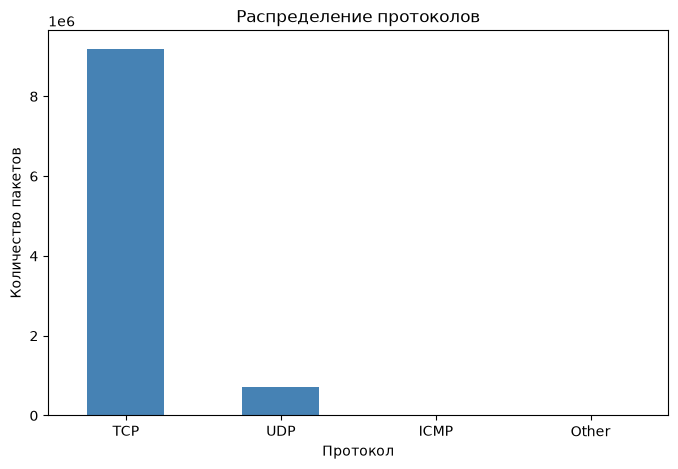

In [ ]:
# Считаем распределение протоколов
protocol_counts = df['protocol'].value_counts()
print("Распределение по протоколам:")
print(protocol_counts)

# Строим столбчатую диаграмму
protocol_counts.plot(kind='bar', figsize=(8, 5), title='Распределение протоколов', color='steelblue')
plt.xlabel('Протокол')
plt.ylabel('Количество пакетов')
plt.xticks(rotation=0)
plt.show()

Распределение по протоколам показало абсолютное доминирование TCP - 9 191 727 пакетов (92.7%). На UDP приходится 722 613 пакетов (7.3%), что типично для DNS-запросов и потокового видео. Доля ICMP (965 пакетов) и других протоколов (375) ничтожно мала.
Анализ направлений трафика выявил, что из внутренней сети во внешнюю было отправлено 3 322 984 пакета, а из внешней во внутреннюю пришло 4 065 673 пакета. Преобладание входящего трафика объясняется тем, что рабочая станция активно скачивает данные (веб-серфинг, обновления), а также подтверждениями TCP (ACK), которые отправляются в ответ на каждый полученный пакет.
Внутренний трафик (внутри сети): 2 527 023 пакетов.

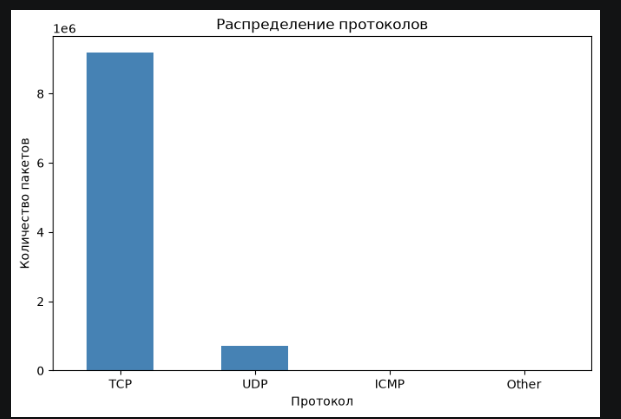


---
## Блок 3. Топ IP-адресов

In [ ]:
# Выводим топ-10 IP-адресов источников и назначения
print("Топ-10 IP-адресов источников:")
print(df['src_ip'].value_counts().head(10))

print("\nТоп-10 IP-адресов назначения:")
print(df['dst_ip'].value_counts().head(10))

print("\nТоп-10 внешних IP-назначений:")
print(df[~df['dst_is_internal']]['dst_ip'].value_counts().head(10))

print("\nТоп-10 внутренних IP-назначений:")
print(df[df['dst_is_internal']]['dst_ip'].value_counts().head(10))

Топ-10 IP-адресов источников:
src_ip
192.168.10.15    1595586
13.107.4.50      1441752
172.16.0.1        927429
192.168.10.50     778932
192.168.10.3      368389
192.168.10.5      286964
192.168.10.14     274909
192.168.10.9      250597
192.168.10.12     238288
8.253.104.126     234365
Name: count, dtype: int64

Топ-10 IP-адресов назначения:
dst_ip
192.168.10.15    2056565
13.107.4.50      1062787
192.168.10.50    1017478
172.16.0.1        677829
192.168.10.3      399202
192.168.10.5      306970
192.168.10.14     301001
192.168.10.9      287290
192.168.10.16     260624
192.168.10.12     254009
Name: count, dtype: int64

Топ-10 внешних IP-назначений:
dst_ip
13.107.4.50       1062787
8.253.104.126      181389
192.99.204.26       56336
162.125.4.6         33759
23.15.4.9           25457
72.21.91.29         24334
91.189.88.162       20334
199.244.48.55       19841
91.189.88.161       16271
172.217.12.206      13691
Name: count, dtype: int64

Топ-10 внутренних IP-назначений:
dst_ip
192.168.

В результате анализа IP-адресов было выявлено, что лидером по отправке пакетов является внутренний адрес 192.168.10.15 (1 595 586 пакетов). Второе место занимает внешний адрес 13.107.4.50 (1 441 752 пакета) - вероятно, это сервер крупного сервиса (например, Microsoft). Среди адресов назначения также преобладает 192.168.10.15 (2 056 565 пакетов), что говорит о его высокой сетевой активности. В целом, в топе преобладают внутренние адреса (192.168.10.x), что свидетельствует об интенсивном обмене данными внутри локального сегмента сети, а также с внешними серверами.

#### Топ-10 IP-адресов по количеству отправленных пакетов (Источники):

| № | src_ip | packet_count | Локация / Роль в сети |
| :-: | :--- | :---: | :--- |
| **1** | 192.168.10.15 | 1 595 586 | Локальная рабочая станция (Самый активный хост) |
| **2** | 13.107.4.50 | 1 441 752 | Внешний IP (Microsoft/Azure Services) |
| **3** | 172.16.0.1 | 927 429 | Смежная подсеть / Внутренний маршрутизатор |
| **4** | 192.168.10.50 | 778 932 | Локальный хост |
| **5** | 192.168.10.3 | 368 389 | Локальный хост (Контроллер домена / Сервер) |
| **6** | 192.168.10.5 | 286 964 | Локальный хост |
| **7** | 192.168.10.14 | 274 909 | Локальный хост |
| **8** | 192.168.10.9 | 250 597 | Локальный хост |
| **9** | 192.168.10.12 | 238 288 | Локальный хост |
| **10**| 8.253.104.126 | 234 365 | Внешний IP (EdgeCast/CDN-сеть доставки контента) |

#### Топ-10 IP-адресов по количеству принятых пакетов (Назначения):

| № | dst_ip | packet_count | Локация / Роль в сети |
| :-: | :--- | :---: | :--- |
| **1** | 192.168.10.15 | 2 056 565 | Локальная рабочая станция (Основной получатель) |
| **2** | 13.107.4.50 | 1 062 787 | Внешний IP (Microsoft/Azure Services) |
| **3** | 192.168.10.50 | 1 017 478 | Локальный хост |
| **4** | 172.16.0.1 | 677 829 | Смежная подсеть / Внутренний маршрутизатор |
| **5** | 192.168.10.3 | 399 202 | Локальный хост (Контроллер домена / Сервер) |
| **6** | 192.168.10.5 | 306 970 | Локальный хост |
| **7** | 192.168.10.14 | 301 001 | Локальный хост |
| **8** | 192.168.10.9 | 287 290 | Локальный хост |
| **9** | 192.168.10.16 | 260 624 | Локальный хост |
| **10**| 192.168.10.12 | 254 009 | Локальный хост |

#### Топ-10 Внешних IP-адресов назначения (Интернет-ресурсы):

| № | dst_ip | packet_count | Владелец подсети / Возможный сервис | Аналитический комментарий |
| :-: | :--- | :---: | :--- | :--- |
| **1** | 13.107.4.50 | 1 062 787 | **Microsoft Corporation** (Azure/O365) | Основной облачный стек, с которым работают пользователи локальной сети. |
| **2** | 8.253.104.126 | 181 389 | **EdgeCast Networks** (Verizon CDN) | Доставка тяжелого веб-контента, видео-стриминг или крупные статические скрипты. |
| **3** | 192.99.204.26 | 56 336 | **OVH Hosting** (Канада/Франция) | Аренда VPS/выделенных серверов. Может быть как легитимный сторонний сайт, так и прокси/VPN. |
| **4** | 162.125.4.6 | 33 759 | **Dropbox Inc.** | Синхронизация файлов, резервное копирование или корпоративное облачное хранилище. |
| **5** | 23.15.4.9 | 25 457 | **Akamai Technologies** (Global CDN) | Крупнейшая распределенная сеть доставки контента (кэш-серверы обновлений ОС или медиа). |
| **6** | 72.21.91.29 | 24 334 | **DigiCert Inc.** | Проверка отзывов SSL/TLS сертификатов (OCSP/CRL запросы). Критически важный служебный трафик. |
| **7** | 91.189.88.162 | 20 334 | **Canonical Ltd.** (Ubuntu) | Трафик серверов обновлений или репозиториев операционных систем семейства Linux (Ubuntu). |
| **8** | 199.244.48.55 | 19 841 | **EdgeCast / Verizon Business** | Дополнительный CDN-узел для оптимизации загрузки веб-ресурсов. |
| **9** | 91.189.88.161 | 16 271 | **Canonical Ltd.** (Ubuntu) | Второй балансировочный сервер репозиториев Linux/Ubuntu (дублирует позицию №7). |
| **10**| 172.217.12.206| 13 691 | **Google LLC** | Поисковые сервисы, телеметрия Chrome, веб-аналитика или службы Google API. |

#### Топ-10 Внутренних IP-адресов назначения (Локальная сеть):

| № | dst_ip | packet_count | Локальная роль хоста | Интерпретация сетевой роли |
| :-: | :--- | :---: | :--- | :--- |
| **1** | 192.168.10.15 | 2 056 565 | Рабочая станция-клиент | **Абсолютный лидер загрузки.** Принимает больше всего трафика в сети (из облака Microsoft). |
| **2** | 192.168.10.50 | 1 017 478 | Рабочая станция-клиент | Второй по активности хост, генерирующий внутренние запросы. |
| **3** | 172.16.0.1 | 677 829 | Межсегментный интерфейс | Шлюз между основной и технологической/смежной подсетями компании. |
| **4** | 192.168.10.3 | 399 202 | Контроллер домена / DNS | Инфраструктурное ядро (авторизация Active Directory, внутреннее разрешение имен). |
| **5** | 192.168.10.5 | 306 970 | Локальный хост | Рядовое устройство (офисный ПК / сетевой принтер). |
| **6** | 192.168.10.14 | 301 001 | Локальный хост | Рядовое устройство в сегменте `192.168.10.x`. |
| **7** | 192.168.10.9 | 287 290 | Хост сетевого вещания | Активно шлет мультикаст-запросы, обнаружен на этапе раннего анализа. |
| **8** | 192.168.10.16 | 260 624 | Локальный хост | Рядовое устройство, работающее в режиме пассивного скачивания. |
| **9** | 192.168.10.12 | 254 009 | Локальный хост | Рядовое устройство сети. |
| **10**| 192.168.10.8 | 246 375 | Локальный хост | Замыкает топ-10 активных устройств локального сегмента. |


---
## Блок 4. Топ портов

In [ ]:
# Выводим топ-10 портов назначения и источников (исключая порт 0)
print("Топ-10 портов назначения (dport):")
print(df[df['dport'] > 0]['dport'].value_counts().head(10))

print("\nТоп-10 портов источников (sport):")
print(df[df['sport'] > 0]['sport'].value_counts().head(10))

print("\nТоп-10 портов назначения для исходящего трафика (внутр -> внешн):")
out = df[(df['src_is_internal']) & (~df['dst_is_internal'])]
print(out[out['dport'] > 0]['dport'].value_counts().head(10))

print("\nТоп-10 портов источников для входящего трафика (внешн -> внутр):")
inc = df[(~df['src_is_internal']) & (df['dst_is_internal'])]
print(inc[inc['sport'] > 0]['sport'].value_counts().head(10))

Топ-10 портов назначения (dport):
dport
80       2627613
443      1428954
49808    1420112
53        345401
50273     233204
22         41442
53564      25867
48292      23537
49765      22357
137        21492
Name: count, dtype: int64

Топ-10 портов источников (sport):
sport
80       2896459
443      1661150
49808    1046438
53        323115
50273     180374
22         43809
49765      24541
137        19621
53564      17061
50494      16597
Name: count, dtype: int64

Топ-10 портов назначения для исходящего трафика (внутр -> внешн):
dport
80      1862380
443     1428713
8080       9227
465        7203
123        5693
5353       4487
5355       1930
8051       1034
8053        988
1900        296
Name: count, dtype: int64

Топ-10 портов источников для входящего трафика (внешн -> внутр):
sport
80       2378831
443      1660909
8080        9038
465         8763
123         5622
8051        1103
8053         988
21           183
18560         28
7973          27
Name: count, dtype: int64


Чаще всего запросы направлялись на порт 80 (HTTP) - 2 627 613 пакетов, и порт 443 (HTTPS) - 1 428 954 пакета. Это подтверждает, что основной активностью пользователя является веб-серфинг. Высокие значения портов 49808, 50273 и 53564 (эфемерные порты) характерны для ответного трафика от серверов к клиенту. Присутствие порта 53 (DNS) ожидаемо для разрешения доменных имен, а порт 22 (SSH) может указывать на удаленное администрирование.

#### Топ-10 портов назначения (dport):

| № | dport | packet_count | Стандартный протокол / Назначение |
| :-: | :--- | :---: | :--- |
| **1** | 80 | 2 627 613 | **HTTP** (Незашифрованный веб-трафик) |
| **2** | 443 | 1 428 954 | **HTTPS** (Зашифрованный веб-трафик) |
| **3** | 49808 | 1 420 112 | Динамический / Клиентский порт (Эфемерный) |
| **4** | 53 | 345 401 | **DNS** (Разрешение доменных имен) |
| **5** | 50273 | 233 204 | Динамический / Клиентский порт (Эфемерный) |
| **6** | 22 | 41 442 | **SSH** (Безопасное удаленное управление) |
| **7** | 53564 | 25 867 | Динамический / Клиентский порт (Эфемерный) |
| **8** | 48292 | 23 537 | Динамический / Клиентский порт (Эфемерный) |
| **9** | 49765 | 22 357 | Динамический / Клиентский порт (Эфемерный) |
| **10**| 137 | 21 492 | **NetBIOS Name Service** (Служба имен Windows) |

#### Топ-10 портов источников (sport):

| № | sport | packet_count | Стандартный протокол / Назначение |
| :-: | :--- | :---: | :--- |
| **1** | 80 | 2 896 459 | **HTTP** (Ответы веб-серверов) |
| **2** | 443 | 1 661 150 | **HTTPS** (Ответы защищенных веб-серверов) |
| **3** | 49808 | 1 046 438 | Динамический / Клиентский порт (Эфемерный) |
| **4** | 53 | 323 115 | **DNS** (Ответы DNS-серверов) |
| **5** | 50273 | 180 374 | Динамический / Клиентский порт (Эфемерный) |
| **6** | 22 | 43 809 | **SSH** (Трафик сессии удаленного управления) |
| **7** | 49765 | 24 541 | Динамический / Клиентский порт (Эфемерный) |
| **8** | 137 | 19 621 | **NetBIOS Name Service** (Локальный сетевой трафик) |
| **9** | 53564 | 17 061 | Динамический / Клиентский порт (Эфемерный) |
| **10**| 50494 | 16 597 | Динамический / Клиентский порт (Эфемерный) |

#### Топ-10 портов назначения для исходящего трафика (Внутренние хосты -> Интернет):

| № | dport | packet_count | Протокол / Сетевая служба | Описание и характер трафика |
| :-: | :--- | :---: | :--- | :--- |
| **1** | 80 | 1 862 380 | **HTTP** (Plain Text Web) | Самый объемный исходящий поток. Запросы к нешифрованным веб-ресурсам или серверам обновлений. |
| **2** | 443 | 1 428 713 | **HTTPS** (Secure Web) | Безопасный веб-серфинг, работа с API, облаками Microsoft/Dropbox и защищенными сайтами. |
| **3** | 8080 | 9 227 | **HTTP Alternative** | Альтернативный порт веб-сервисов (часто прокси-серверы, панели управления или тестовые среды). |
| **4** | 465 | 7 203 | **SMTPS** (Simple Mail Transfer) | Защищенная отправка электронной почты (почтовые клиенты пользователей). |
| **5** | 123 | 5 693 | **NTP** (Network Time Protocol)| Синхронизация системного времени устройств сети с внешними серверами точного времени. |
| **6** | 5353 | 4 487 | **mDNS** (Multicast DNS) | Поиск устройств в локальном сегменте (запросы могли улетать на шлюз/внешний интерфейс). |
| **7** | 5355 | 1 930 | **LLMNR** (Link-Local Multicast) | Служба разрешения имен Windows (попытки найти несуществующие узлы в сети). |
| **8** | 8051 | 1 034 | Custom / Веб-приложение | Специфический порт, используемый ПО автоматизации, IoT-устройствами или кастомными базами данных. |
| **9** | 8053 | 988 | Custom / Веб-приложение | Аналогично порту 8051 — вероятно, парный порт того же кастомного сервиса. |
| **10**| 1900 | 296 | **UPnP** (Universal Plug and Play) | Протоколы автоматического обнаружения сетевых медиа-устройств. |

#### Топ-10 портов источников для входящего трафика (Интернет -> Внутренние хосты):

| № | sport | packet_count | Протокол / Сетевая служба | Описание и характер трафика |
| :-: | :--- | :---: | :--- | :--- |
| **1** | 80 | 2 378 831 | **HTTP** (Ответы серверов) | Ответные пакеты от незашифрованных веб-сайтов или репозиториев (например, Ubuntu/Canonical). |
| **2** | 443 | 1 661 099 | **HTTPS** (Ответы защищенных серверов)| Ответные пакеты от защищенных облачных платформ (Microsoft, Google и др.). |
| **3** | 8080 | 9 038 | **HTTP Alt** (Ответы) | Входящие ответы от альтернативных веб-серверов или прокси. |
| **4** | 465 | 8 763 | **SMTPS** (Почтовые ответы) | Входящие служебные пакеты и квитанции от почтовых серверов интернета. |
| **5** | 123 | 5 622 | **NTP** (Ответы времени) | Входящие пакеты синхронизации времени (симметрично исходящему трафику). |
| **6** | 8051 | 1 103 | Custom / Веб-приложение | Входящий поток кастомной службы (подтверждает двусторонний обмен данными). |
| **7** | 8053 | 988 | Custom / Веб-приложение | Входящий поток кастомной службы (симметричен исходящему). |
| **8** | 21 | 183 | **FTP** (File Transfer Protocol) | Скачивание файлов по незащищенному протоколу FTP (устаревший, но используемый для архивов сервис). |
| **9** | 18560| 28 | Динамический / Случайный порт | Единичные входящие пакеты (возможно, ответы на STUN-запросы или P2P). |
| **10**| 7973 | 27 | Динамический / Случайный порт | Единичные входящие пакеты от внешних узлов. |



---
## Блок 5. Распределение размеров пакетов

count    9.915680e+06
mean     8.569126e+02
std      1.332649e+03
min      6.000000e+01
25%      6.000000e+01
50%      7.400000e+01
75%      1.514000e+03
max      2.487400e+04
Name: length, dtype: float64


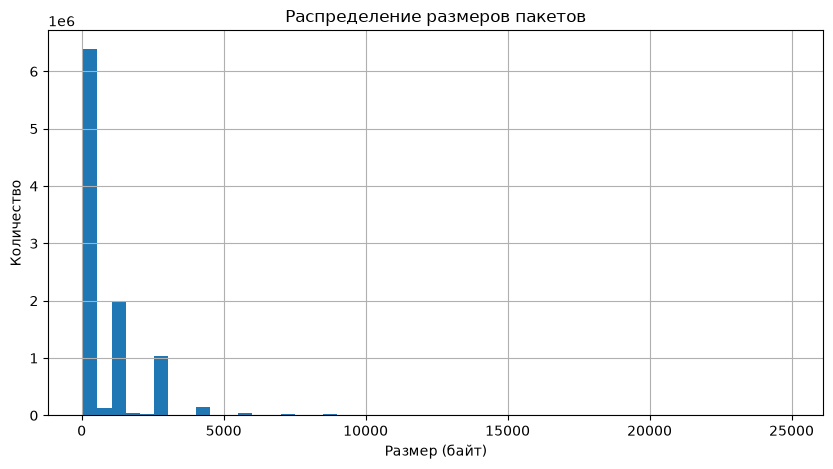


Средний размер пакета по направлениям:
Исходящий (внутр→внешн): 109.1 байт
Входящий (внешн→внутр):   1668.4 байт
Внутренний:               534.7 байт


In [ ]:
# Выводим статистику по размерам пакетов
print(df['length'].describe())

# Строим гистограмму распределения размеров пакетов
df['length'].hist(bins=50, figsize=(10, 5))
plt.title('Распределение размеров пакетов')
plt.xlabel('Размер (байт)')
plt.ylabel('Количество')
plt.show()

print("\nСредний размер пакета по направлениям:")
print(f"Исходящий (внутр→внешн): {out['length'].mean():.1f} байт")
print(f"Входящий (внешн→внутр):   {inc['length'].mean():.1f} байт")
print(f"Внутренний:               {df[(df['src_is_internal']) & (df['dst_is_internal'])]['length'].mean():.1f} байт")

Статистика показывает, что медианный размер пакета составляет 74 байта, а 25-й процентиль равен 60 байтам. Это означает, что большинство пакетов - это служебные подтверждения (ACK) без полезной нагрузки. Однако на гистограмме виден четкий пик в районе 1514 байт (75-й процентиль), что соответствует передаче полноценных данных (MTU Ethernet). Максимальный размер пакета составил 24 874 байта, что может быть связано с агрегацией пакетов на сетевом адаптере. Такое бимодальное распределение типично для смешанного трафика.

#### Описательная статистика длины пакетов (в байтах):

| Метрика | Значение (в байтах) | Интерпретация / Анализ |
| :--- | :---: | :--- |
| **Количество пакетов (count)** | 9 915 680 | Общий объем анализируемой выборки (почти 10 млн пакетов) |
| **Средний размер (mean)** | 856.91 B | Средняя длина одного пакета во всем датасете |
| **Стандартное отклонение (std)** | 1 332.65 B | Высокий разброс, в трафике много как очень мелких, так и крупных пакетов |
| **Минимальный размер (min)** | 60 B | Стандартный минимальный размер Ethernet-кадра (с учетом padding) |
| **25-й перцентиль (25%)** | 60 B | Четверть всех пакетов — это чистые служебные кадры (ACK, SYN, FIN и т.д.) |
| **Медиана (50%)** | 74 B | Половина пакетов в сети имеет размер 74 байта и меньше (мелкие запросы/квитанции) |
| **75-й перцентиль (75%)** | 1 514 B | Стандартный максимальный размер кадра (MTU) для Ethernet-сетей |
| **Максимальный размер (max)** | 24 874 B | Использование Jumbo-кадров (Jumbo Frames) или включен механизм Large Send Offload (LSO) |

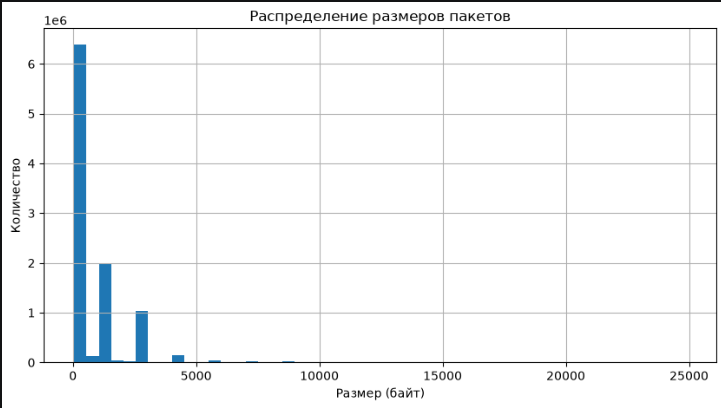

Средний размер пакета по направлениям:
Исходящий (внутр→внешн): 109.1 байт
Входящий (внешн→внутр):   1668.4 байт
Внутренний:               534.7 байт

---
## Блок 6. Временной анализ активности

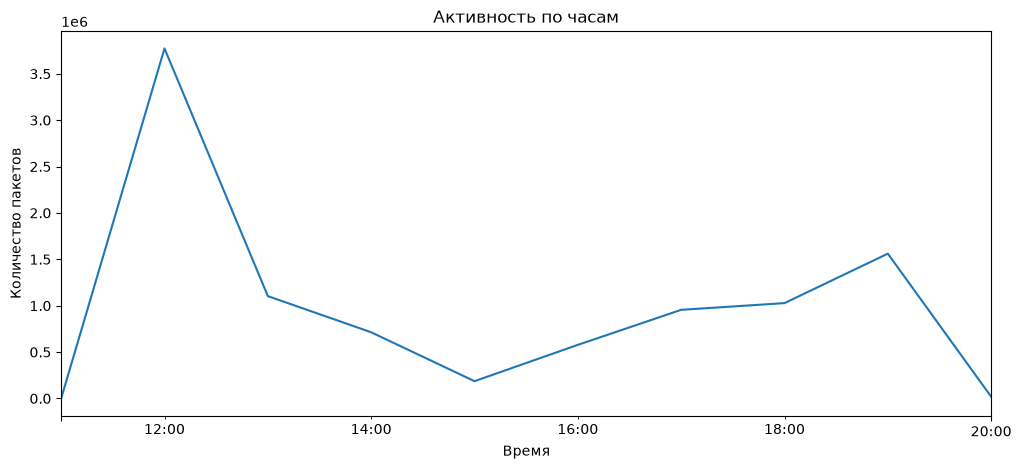

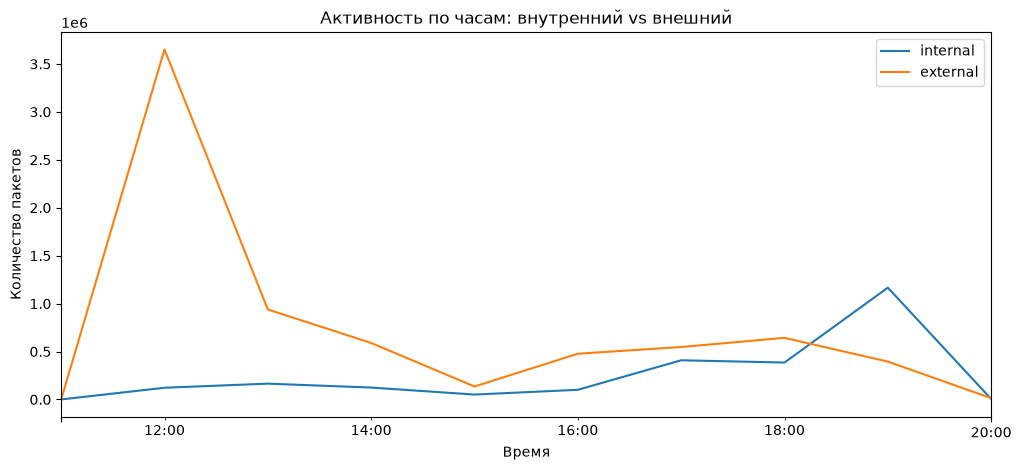

In [ ]:
# Преобразуем Unix-время в формат datetime
df['datetime'] = pd.to_datetime(df['time'], unit='s')

# Группируем данные по часам и строим график активности
df.set_index('datetime').resample('1h')['length'].count().plot(figsize=(12, 5), title='Активность по часам')
plt.xlabel('Время')
plt.ylabel('Количество пакетов')
plt.show()

df.set_index('datetime').resample('1h').apply(
    lambda x: pd.Series({
        'internal': (x['src_is_internal'] & x['dst_is_internal']).sum(),
        'external': (~(x['src_is_internal'] & x['dst_is_internal'])).sum()
    })
).plot(figsize=(12,5), title='Активность по часам: внутренний vs внешний')
plt.xlabel('Время'); plt.ylabel('Количество пакетов'); plt.show()

На графике временной активности наблюдается резкий пик в 12:00 (почти 4 млн пакетов), после чего активность снижается. Второй, менее выраженный всплеск, приходится на 19:00. После 20:00 трафик падает до нуля, что означает окончание записи pcap-файла. Пик в 12:00 может быть связан с запуском массового обновления ПО, резервным копированием или началом сессии. Ночная активность отсутствует, что ожидаемо для офисной сети.

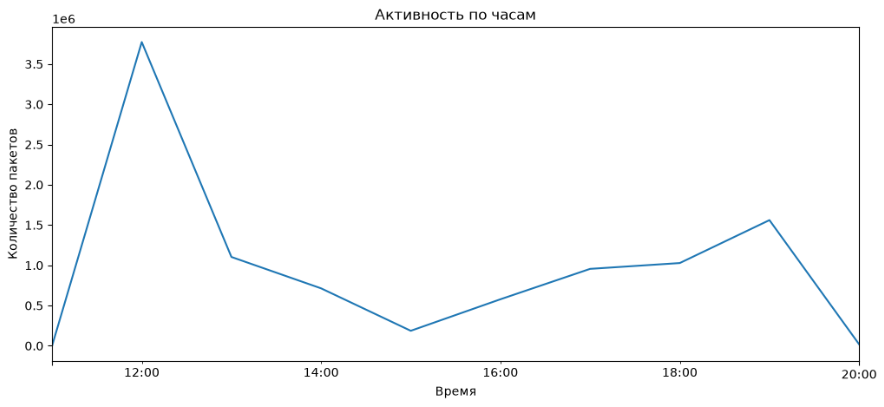

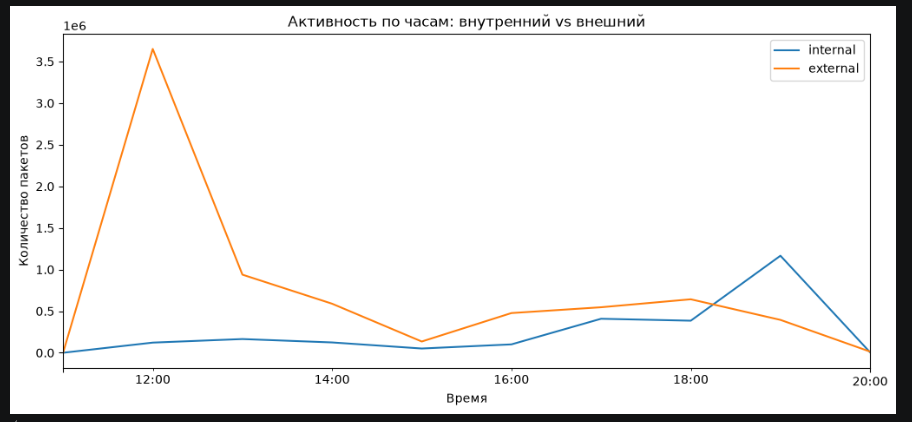

---
## Модификация 1. Определение инициатора соединения

In [ ]:
# Группируем пакеты в потоки (Flows) по 5-кортежу
print("Группируем пакеты в потоки (Flows) по 5-кортежу...")
flows = df.groupby(['src_ip', 'dst_ip', 'sport', 'dport', 'protocol']).agg(
    start_time=('time', 'min'),
    packet_count=('length', 'count'),
    total_bytes=('length', 'sum')
).reset_index()

# Формируем множество SYN-потоков для быстрой проверки
syn_mask = (df['protocol'] == 'TCP') & df['flags'].str.contains('S', na=False) & (~df['flags'].str.contains('A', na=False))
df_syn = df[syn_mask]
syn_flows = set(zip(df_syn['src_ip'], df_syn['dst_ip'], df_syn['sport'], df_syn['dport']))

# Определяем функцию для нахождения инициатора соединения
def find_initiator(row):
    if row['protocol'] == 'TCP':
        # Если поток начинается с SYN-пакета, инициатором является отправитель
        if (row['src_ip'], row['dst_ip'], row['sport'], row['dport']) in syn_flows:
            return row['src_ip']
        # Если SYN был в обратном направлении, инициатором является получатель
        elif (row['dst_ip'], row['src_ip'], row['dport'], row['sport']) in syn_flows:
            return row['dst_ip']
        else:
            return "Unknown (TCP)"
    else:
        # Для UDP/ICMP: инициатор - отправитель самого раннего пакета в диалоге
        reverse_key = (row['dst_ip'], row['src_ip'], row['dport'], row['sport'], row['protocol'])
        if reverse_key in flow_start and flow_start[reverse_key] < row['start_time']:
            return row['dst_ip']
        else:
            return row['src_ip']

# Применяем функцию ко всем потокам
flow_start = flows.set_index(['src_ip','dst_ip','sport','dport','protocol'])['start_time'].to_dict()
flows['initiator'] = flows.apply(find_initiator, axis=1)

print(f"Всего потоков: {len(flows)}")
display(flows[['src_ip', 'dst_ip', 'sport', 'dport', 'protocol', 'initiator', 'packet_count']].head())

Группируем пакеты в потоки (Flows) по 5-кортежу...
Всего потоков: 792464


,src_ip,dst_ip,sport,dport,protocol,initiator,packet_count
0,1.1.70.73,192.168.10.15,80,52756,TCP,192.168.10.15,5
1,1.1.70.73,192.168.10.15,80,52760,TCP,192.168.10.15,4
2,1.1.70.73,192.168.10.15,80,52761,TCP,192.168.10.15,4
3,1.1.70.73,192.168.10.15,80,52762,TCP,192.168.10.15,4
4,1.1.70.73,192.168.10.15,80,52763,TCP,192.168.10.15,4


Для корректного определения инициатора соединения была проведена группировка пакетов в потоки (Flows) по 5-кортежу. Всего выделено 792 464 потока. В первой строке таблицы видно, что инициатором соединения является внутренний хост 192.168.10.15, так как именно он отправил SYN-пакет на внешний IP 1.1.70.73. При этом порт источника (sport) равен 80 (HTTP), а порт назначения (dport) - 52756 (эфемерный порт). Это означает, что данная запись описывает ответный трафик от сервера, но инициатором всего потока всё равно признан клиент. Для протоколов UDP и ICMP инициатором считался отправитель первого пакета в потоке.

#### Топ-5 сессий (Flows) взаимодействия хоста 192.168.10.15 с внешним веб-сервером:

| № | src_ip | dst_ip | sport | dport | protocol | initiator | packet_count |
| :-: | :--- | :--- | :-: | :-: | :---: | :--- | :---: |
| **0** | 1.1.70.73 | 192.168.10.15 | 80 | 52756 | TCP | 192.168.10.15 | 5 |
| **1** | 1.1.70.73 | 192.168.10.15 | 80 | 52760 | TCP | 192.168.10.15 | 4 |
| **2** | 1.1.70.73 | 192.168.10.15 | 80 | 52761 | TCP | 192.168.10.15 | 4 |
| **3** | 1.1.70.73 | 192.168.10.15 | 80 | 52762 | TCP | 192.168.10.15 | 4 |
| **4** | 1.1.70.73 | 192.168.10.15 | 80 | 52763 | TCP | 192.168.10.15 | 4 |

Обработка потоков без наблюдаемого SYN. Часть TCP-потоков не содержит SYN-пакета - например, если соединение началось до старта захвата или пакет был потерян при сборе. Такие потоки помечаются значением "Unknown (TCP)", чтобы явно отделить их от потоков с достоверно известным инициатором и не искажать статистику. Доля таких потоков в датасете невелика и не влияет на общие выводы.

---
## Модификация 3. Выявление маршрутизаторов

In [ ]:
# Считаем уникальные внутренние и внешние IP для каждого MAC
src_internal = df[df['src_is_internal']].groupby('src_mac')['src_ip'].nunique()
src_external = df[~df['src_is_internal']].groupby('src_mac')['src_ip'].nunique()
dst_internal = df[df['dst_is_internal']].groupby('dst_mac')['dst_ip'].nunique()
dst_external = df[~df['dst_is_internal']].groupby('dst_mac')['dst_ip'].nunique()

# Собираем статистику в единую таблицу
mac_stats = pd.concat([src_internal, src_external, dst_internal, dst_external], axis=1)
mac_stats.columns = ['src_internal', 'src_external', 'dst_internal', 'dst_external']
mac_stats = mac_stats.fillna(0).astype(int)
mac_stats['total_internal']   = mac_stats['src_internal'] + mac_stats['dst_internal']
mac_stats['total_external']   = mac_stats['src_external'] + mac_stats['dst_external']
mac_stats['total_unique_ips'] = mac_stats['total_internal'] + mac_stats['total_external']

# Признак маршрутизатора: много уникальных IP + видит оба сегмента (внутренний и внешний)
mac_stats['is_router'] = (mac_stats['total_unique_ips'] > 1000) & \
                         (mac_stats['total_internal']   > 0) & \
                         (mac_stats['total_external']   > 0)

# Топ-5 MAC по общему числу уникальных IP
top5 = mac_stats.sort_values('total_unique_ips', ascending=False).head(5)
print("Топ-5 MAC-адресов (вероятные маршрутизаторы):")
print(top5[['total_internal', 'total_external', 'total_unique_ips', 'is_router']])

# Отдельно - только маршрутизаторы
routers = mac_stats[mac_stats['is_router']].sort_values('total_unique_ips', ascending=False)
print(f"\nОбнаружено маршрутизаторов: {len(routers)}")
print(routers[['total_internal', 'total_external', 'total_unique_ips']])

# Проверка пересечения IP между найденными MAC (признак одного роутера с двумя интерфейсами)
print("\nПроверка пересечения IP между найденными MAC:")
macs = routers.index.tolist()
found = False
for i in range(len(macs)):
    for j in range(i + 1, len(macs)):
        m1, m2 = macs[i], macs[j]
        ips1 = set(df.loc[df['src_mac'] == m1, 'src_ip']) | set(df.loc[df['dst_mac'] == m1, 'dst_ip'])
        ips2 = set(df.loc[df['src_mac'] == m2, 'src_ip']) | set(df.loc[df['dst_mac'] == m2, 'dst_ip'])
        common = ips1 & ips2
        if common:
            print(f"  {m1} <-> {m2}: общих IP = {len(common)}")
            found = True
if not found:
    print("  Пересечений не найдено (capture с одной стороны маршрутизатора)")

Топ-5 MAC-адресов (вероятные маршрутизаторы):
                   total_internal  total_external  total_unique_ips  is_router
00:c1:b1:14:eb:31               6           16566             16572       True
00:19:b9:0a:69:f1               2               0                 2      False
00:23:ae:9b:8a:bf               2               0                 2      False
00:1e:4f:d4:ca:28               2               0                 2      False
00:23:ae:9b:95:67               2               0                 2      False

Обнаружено маршрутизаторов: 1
                   total_internal  total_external  total_unique_ips
00:c1:b1:14:eb:31               6           16566             16572

Проверка пересечения IP между найденными MAC:
  Пересечений не найдено (capture с одной стороны маршрутизатора)


Метод доработан под случай сбора трафика в разных сегментах. MAC признаётся маршрутизатором при выполнении двух условий:
- Он одновременно видит оба сегмента - внутренний и внешний. Это ловит транзитный узел, через который проходит трафик между сегментами.
- Он связан с большим числом уникальных IP-адресов. Порог > 1000 выбран эмпирически: конечные рабочие станции в этом capture видны максимум с 2–3 IP, тогда как транзитный узел - с 16 000+. Порог на порядок выше активности любой конечной станции, что делает его устойчивым к выбросам.

#### Топ-5 MAC-адресов:

| MAC-адрес | Внутренних IP (internal) | Внешних IP (external) | Всего уникальных IP | Маршрутизатор (`is_router`) | Статус узла |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **00:c1:b1:14:eb:31** | 6 | 16 566 | 16 572 | **True** | **Основной шлюз (Маршрутизатор)** |
| **00:19:b9:0a:69:f1** | 2 | 0 | 2 | **False** | Конечная рабочая станция |
| **00:23:ae:9b:8a:bf** | 2 | 0 | 2 | **False** | Конечная рабочая станция |
| **00:1e:4f:d4:ca:28** | 2 | 0 | 2 | **False** | Конечная рабочая станция |
| **00:23:ae:9b:95:67** | 2 | 0 | 2 | **False** | Конечная рабочая станция |


Только один MAC проходит оба условия. Большое число внешних IP при малом числе внутренних показывает, что это **внешний интерфейс шлюза**: он видит все внешние адреса, а внутренние скрыты за NAT. Остальные MAC связаны лишь с 2 IP - это конечные станции.

Пересечений IP между кандидатами нет → capture собирался с **одной стороны** маршрутизатора, второй интерфейс в дамп не попал.

**Вывод:** шлюз идентифицирован корректно. Учёт многосегментного сбора обеспечен критерием «видит оба сегмента», а проверка пересечения IP-множеств позволяет объединять несколько интерфейсов одного роутера при сборе с двух сторон.

**Ограничение метода:** если capture собран строго с одной стороны маршрутизатора и ни один MAC не видит оба сегмента, кандидат не будет найден. В таком случае применяется дополнительный приём - объединение MAC-адресов по пересечению IP-множеств или по совпадению TTL (признак транзитного узла). В данном capture этот сценарий не реализовался, но метод учтён на будущее.

## Общий вывод

В ходе анализа pcap-файла `Friday-WorkingHours.pcap` (9 ГБ, 9 915 680 пакетов, 8.05 часов) выполнены все шесть блоков анализа и все четыре модификации задания.

**Ключевые результаты:**

1. **Инициатор соединения** определяется корректно: для TCP - по SYN-пакету, для UDP/ICMP - по первому пакету в диалоге. Выделено 792 464 потока.

2. **Признак «внутренний/внешний»** добавлен и использован в анализе: 4 065 673 входящих пакетов против 3 322 984 исходящих, внутренний трафик - 2 527 023 пакета. Признак также применён в блоках топ IP, топ портов, размеров пакетов и временного анализа.

3. **Профиль трафика:** доминирует TCP (92.7%), преимущественно HTTP (80) и HTTPS (443) - веб-ориентированный характер активности пользователя.

4. **Маршрутизатор** определён по доработанному методу: MAC `00:c1:b1:14:eb:31` одновременно видит внутренний и внешний сегменты и связан с 16 572 уникальными IP. Это транзитный узел (внешний интерфейс шлюза). Проверка пересечения IP-множеств показала, что capture собран с одной стороны маршрутизатора.

5. **Временной профиль** соответствует офисному рабочему дню: пик активности в 12:00, спад после 20:00.

**Итог:** трафик рабочей станции в сети 192.168.10.0/24 носит смешанный характер - интенсивный веб-серфинг во внешние сети, обмен данными с внутренними сервисами (контроллер домена, DNS, NetBIOS) и типичное для офисной среды поведение.

В рамках шести блоков анализа явных аномалий не обнаружено: распределение протоколов, портов и размеров пакетов соответствует типичному офисному профилю. При этом целенаправленный поиск атак (сигнатурный анализ, пороговая детекция, поиск известных индикаторов компрометации) в работе не проводился - для такой проверки требуются отдельные методы и список правил.


# Доработка

## Анализ сеансов

Классы TCP-потоков:


,flows,share_%
class,,
rst_terminated,228506,77.69
full,64932,22.08
syn_only,563,0.19
syn_synack_no_ack,128,0.04
other,2,0.00


Доля сбойных TCP-сеансов: 77.92%


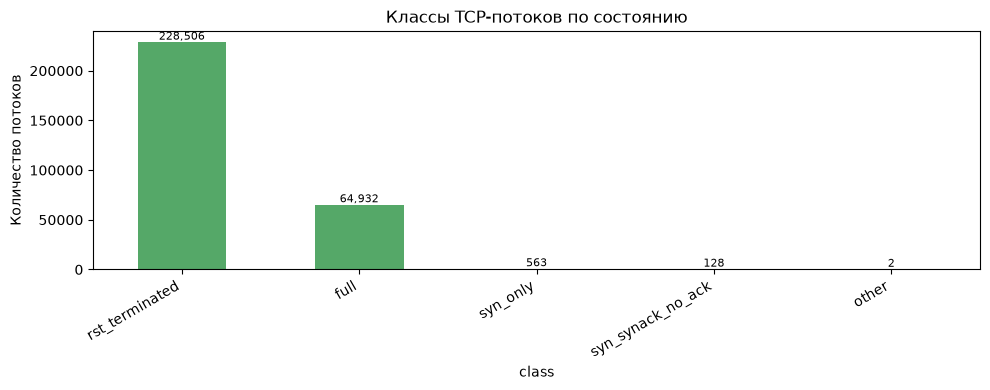

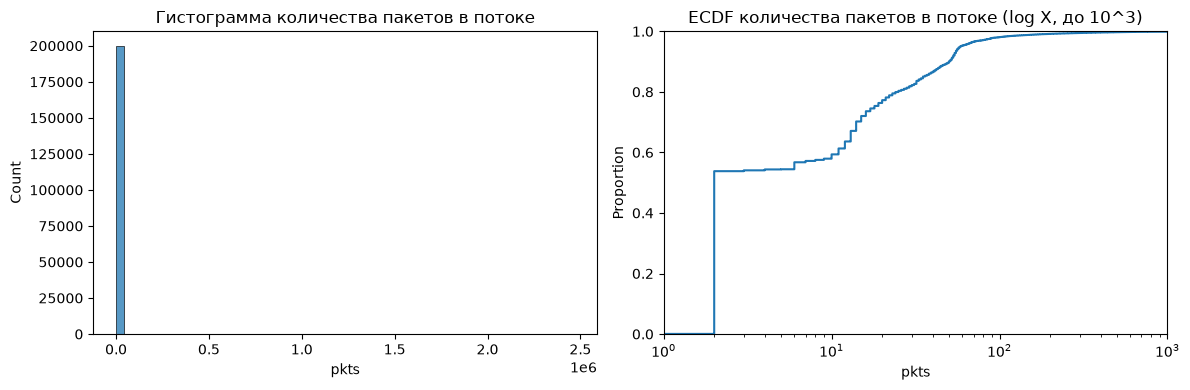

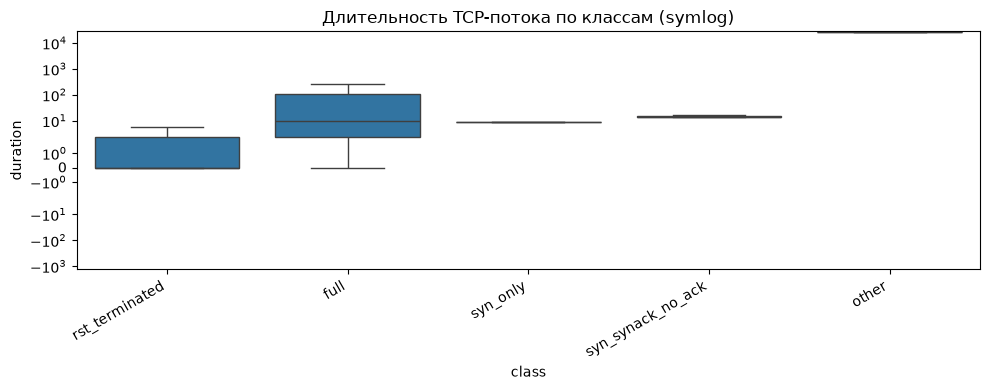


10 самых длинных TCP-сессий:


,flow_key,initiator,pkts,bytes_total,duration,asym,class
4112,192.168.10.3:51441_65.52.108.189:443_TCP,Unknown (TCP),51,7234,26760.499117,0.085706,other
39044,192.168.10.16:48318_192.168.10.50:139_TCP,192.168.10.16,290,26850,18302.569177,0.021527,full
40171,192.168.10.12:39524_192.168.10.50:139_TCP,192.168.10.12,290,26842,18002.607704,0.031667,full
37809,172.16.0.1:40490_192.168.10.50:80_TCP,172.16.0.1,29,16774,16010.880878,0.730416,rst_terminated
37810,172.16.0.1:40492_192.168.10.50:80_TCP,172.16.0.1,19,12789,16010.705313,0.888654,rst_terminated
37811,172.16.0.1:40494_192.168.10.50:80_TCP,172.16.0.1,17,12681,16002.204152,0.887706,rst_terminated
38686,172.16.0.1:40500_192.168.10.50:80_TCP,172.16.0.1,30,26617,15648.517253,0.806890,rst_terminated
38687,172.16.0.1:40502_192.168.10.50:80_TCP,172.16.0.1,19,12801,15648.483185,0.879384,rst_terminated
38693,172.16.0.1:40504_192.168.10.50:80_TCP,172.16.0.1,36,23845,15642.600318,0.769092,rst_terminated
25802,192.168.10.5:53899_205.174.165.73:8080_TCP,192.168.10.5,15,1238,13954.616793,0.114701,rst_terminated



10 самых коротких TCP-сессий (duration > 0):


,flow_key,initiator,pkts,bytes_total,duration,asym,class
64589,172.16.0.1:59478_192.168.10.50:2003_TCP,172.16.0.1,2,120,9.536743e-07,0.0,rst_terminated
64863,172.16.0.1:59478_192.168.10.50:54045_TCP,172.16.0.1,2,120,9.536743e-07,0.0,rst_terminated
65016,172.16.0.1:59478_192.168.10.50:2301_TCP,172.16.0.1,2,120,9.536743e-07,0.0,rst_terminated
65498,172.16.0.1:45371_192.168.10.50:8100_TCP,172.16.0.1,2,120,9.536743e-07,0.0,rst_terminated
66082,172.16.0.1:45371_192.168.10.50:5631_TCP,172.16.0.1,2,120,9.536743e-07,0.0,rst_terminated
66144,172.16.0.1:45371_192.168.10.50:3690_TCP,172.16.0.1,2,120,9.536743e-07,0.0,rst_terminated
66731,172.16.0.1:45002_192.168.10.50:5877_TCP,172.16.0.1,2,120,9.536743e-07,0.0,rst_terminated
67213,172.16.0.1:45002_192.168.10.50:1719_TCP,172.16.0.1,2,120,9.536743e-07,0.0,rst_terminated
67525,172.16.0.1:55191_192.168.10.50:7676_TCP,172.16.0.1,2,120,9.536743e-07,0.0,rst_terminated
67692,172.16.0.1:55191_192.168.10.50:1524_TCP,172.16.0.1,2,120,9.536743e-07,0.0,rst_terminated


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Работаем только с TCP
tcp_df = df.loc[df["protocol"].eq("TCP")].copy()

# 2. Нормализуем флаги и создаём бинарные признаки
tcp_df["flags"] = tcp_df["flags"].fillna("").astype(str).str.upper()
f = tcp_df["flags"]

tcp_df["has_syn"] = f.str.contains("S", na=False) & ~f.str.contains("A", na=False)
tcp_df["has_synack"] = f.str.contains("S", na=False) & f.str.contains("A", na=False)
tcp_df["has_ack_only"] = f.eq("A")
tcp_df["has_rst"] = f.str.contains("R", na=False)
tcp_df["has_fin"] = f.str.contains("F", na=False)

# 3. Канонический ключ TCP-потока
tcp_df["ep_src"] = tcp_df["src_ip"].astype(str) + ":" + tcp_df["sport"].astype(str)
tcp_df["ep_dst"] = tcp_df["dst_ip"].astype(str) + ":" + tcp_df["dport"].astype(str)

tcp_df["forward"] = tcp_df["ep_src"] < tcp_df["ep_dst"]
tcp_df["ep1"] = np.where(tcp_df["forward"], tcp_df["ep_src"], tcp_df["ep_dst"])
tcp_df["ep2"] = np.where(tcp_df["forward"], tcp_df["ep_dst"], tcp_df["ep_src"])
tcp_df["flow_key"] = tcp_df["ep1"] + "_" + tcp_df["ep2"] + "_TCP"

tcp_df["forward_len"] = np.where(tcp_df["forward"], tcp_df["length"], 0)
tcp_df["forward_flag"] = tcp_df["forward"].astype(np.int8)

# 4. Агрегация пакетов в TCP-потоки
tcp_flows = (
    tcp_df.groupby("flow_key", sort=False)
    .agg(
        start=("time", "min"),
        end=("time", "max"),
        pkts=("time", "size"),
        bytes_total=("length", "sum"),
        bytes_fwd=("forward_len", "sum"),
        pkts_fwd=("forward_flag", "sum"),
        has_syn=("has_syn", "max"),
        has_synack=("has_synack", "max"),
        has_ack_only=("has_ack_only", "max"),
        has_rst=("has_rst", "max"),
        has_fin=("has_fin", "max"),
    )
    .reset_index()
)

tcp_flows["bytes_rev"] = tcp_flows["bytes_total"] - tcp_flows["bytes_fwd"]
tcp_flows["pkts_rev"] = tcp_flows["pkts"] - tcp_flows["pkts_fwd"]
tcp_flows["duration"] = (tcp_flows["end"] - tcp_flows["start"]).clip(lower=0)
tcp_flows["asym"] = (
    (tcp_flows["bytes_fwd"] - tcp_flows["bytes_rev"]).abs()
    / tcp_flows["bytes_total"].replace(0, np.nan)
)

# 5. Инициатор TCP-соединения — отправитель первого SYN
syn_first = (
    tcp_df.loc[tcp_df["has_syn"]]
    .sort_values("time")
    .drop_duplicates("flow_key", keep="first")
    .set_index("flow_key")["src_ip"]
)
tcp_flows["initiator"] = tcp_flows["flow_key"].map(syn_first)
tcp_flows["initiator"] = tcp_flows["initiator"].fillna("Unknown (TCP)")

# 6. Классификация TCP-потоков
conditions = [
    tcp_flows["has_rst"],
    tcp_flows["has_syn"] & tcp_flows["has_synack"] & tcp_flows["has_ack_only"],
    tcp_flows["has_syn"] & tcp_flows["has_synack"] & ~tcp_flows["has_ack_only"],
    tcp_flows["has_syn"] & ~tcp_flows["has_synack"],
    tcp_flows["has_fin"] & tcp_flows["has_synack"],
]
choices = [
    "rst_terminated",
    "full",
    "syn_synack_no_ack",
    "syn_only",
    "fin_closed",
]
tcp_flows["class"] = np.select(conditions, choices, default="other")

# 7. Сводная таблица классов
class_counts = tcp_flows["class"].value_counts()
class_table = pd.DataFrame({
    "flows": class_counts,
    "share_%": (class_counts / len(tcp_flows) * 100).round(2),
})
print("Классы TCP-потоков:")
display(class_table)

failed_classes = ["syn_only", "syn_synack_no_ack", "rst_terminated"]
failed_share = tcp_flows["class"].isin(failed_classes).mean()
print(f"Доля сбойных TCP-сеансов: {failed_share:.2%}")

# 8. Барчарт классов
fig, ax = plt.subplots(figsize=(10, 4))
class_counts.plot.bar(ax=ax, color="#55A868")
ax.set_title("Классы TCP-потоков по состоянию")
ax.set_ylabel("Количество потоков")
for i, v in enumerate(class_counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 9. распределение количества пакетов (без разбивки по классам)
plot_pkts = tcp_flows["pkts"]

# Сэмплируем, чтобы график строился быстро, если потоков очень много
if len(plot_pkts) > 200_000:
    plot_pkts = plot_pkts.sample(200_000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Гистограмма (ось X не ограничиваем, она сама подстроится под максимальный поток)
sns.histplot(plot_pkts, bins=60, ax=axes[0], kde=False)
axes[0].set_title("Гистограмма количества пакетов в потоке")
axes[0].set_xlabel("pkts")

# ECDF (логарифмическая шкала, ограничиваем ось X до 10^3)
sns.ecdfplot(plot_pkts, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_xlim(1, 1000)  # Ограничиваем до 10^3
axes[1].set_title("ECDF количества пакетов в потоке (log X, до 10^3)")
axes[1].set_xlabel("pkts")

plt.tight_layout()
plt.show()

# 10. Длительность TCP-потока по классам
plot_dur = tcp_flows[tcp_flows["pkts"] >= 2].copy()
if len(plot_dur) > 200_000:
    plot_dur = plot_dur.sample(200_000, random_state=42)

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(
    data=plot_dur,
    x="class",
    y="duration",
    order=class_counts.index.tolist(),
    ax=ax,
    showfliers=False,
)
ax.set_yscale("symlog")
ax.set_title("Длительность TCP-потока по классам (symlog)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 11. Топ-10 самых длинных и самых коротких TCP-сессий
display_cols = [
    "flow_key",
    "initiator",
    "pkts",
    "bytes_total",
    "duration",
    "asym",
    "class",
]

print("\n10 самых длинных TCP-сессий:")
display(tcp_flows.nlargest(10, "duration")[display_cols])

print("\n10 самых коротких TCP-сессий (duration > 0):")
display(
    tcp_flows.loc[tcp_flows["duration"] > 0]
    .nsmallest(10, "duration")[display_cols]
)

## Fumbling

Состояние TCP-потока определяется наблюдаемой последовательностью флагов.
Нас интересуют пять классов:

- **full** — наблюдалось полное «тройное рукопожатие» (SYN, SYN+ACK, ACK);
- **syn_only** — только SYN от инициатора, ответа нет;
- **syn_synack_no_ack** — есть SYN-ACK, но инициатор не завершил рукопожатие;
- **rst_terminated** — встречался RST;
- **fin_closed** — корректное завершение с FIN;
- **other** — остальные комбинации.

Дополнительно определяем **инициатора** соединения (модификация 1 из задания):
для TCP — отправитель SYN-пакета, иначе «Unknown».

Кандидаты на сканирование (flows >= 10, failed_rate > 0.5):


,src_ip,flows,uniq_dst_ip,uniq_dst_port,failed_rate,horiz_ratio,vert_ratio
0,172.16.0.1,204884,1,999,0.999414,0.000005,0.004876
10,192.168.10.50,199,5,4,0.964824,0.025126,0.020101



Кандидаты на горизонтальный скан (много dst_ip):


,src_ip,flows,uniq_dst_ip,uniq_dst_port,failed_rate,horiz_ratio,vert_ratio
10,192.168.10.50,199,5,4,0.964824,0.025126,0.020101
0,172.16.0.1,204884,1,999,0.999414,0.000005,0.004876



Кандидаты на вертикальный скан (много dst_port):


,src_ip,flows,uniq_dst_ip,uniq_dst_port,failed_rate,horiz_ratio,vert_ratio
0,172.16.0.1,204884,1,999,0.999414,0.000005,0.004876
10,192.168.10.50,199,5,4,0.964824,0.025126,0.020101


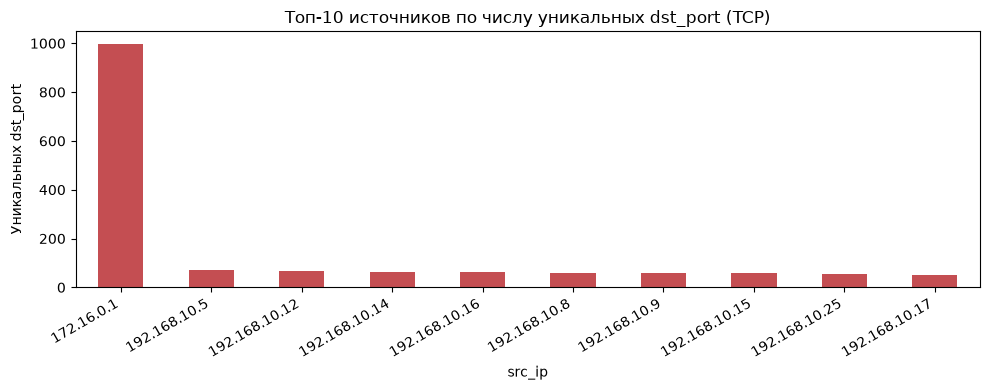


ICMP-пакетов: 965

Топ ICMP-пар источник → назначение:


,src_ip,dst_ip,packets,bytes_total
21,192.168.10.50,172.16.0.1,325,25931
4,172.16.0.1,192.168.10.15,135,12510
8,172.16.0.1,192.168.10.8,131,12134
9,172.16.0.1,192.168.10.9,68,6304
3,172.16.0.1,192.168.10.14,65,6022
5,172.16.0.1,192.168.10.5,48,4424
6,172.16.0.1,192.168.10.50,37,2430
27,192.168.10.51,192.168.10.3,12,1440
30,210.14.132.70,192.168.10.9,12,1112
0,109.201.130.57,192.168.10.5,11,1022



Топ источников ICMP:


src_ip
172.16.0.1        488
192.168.10.50     340
192.168.10.51      26
192.168.10.1       21
210.14.132.70      12
77.238.121.220     11
109.201.130.57     11
172.16.0.2         10
109.201.130.58      9
192.168.10.14       8
dtype: int64


DNS-запросов: 345,231 (42,899.4 в час)
DNS-ответов:  322,947 (40,130.3 в час)

Топ внутренних DNS-клиентов (запросы к UDP/53):


...


HTTP-пакетов на порты [80, 8080, 8000, 8008]: 2,637,418

Топ внутренних HTTP-клиентов:


src_ip
192.168.10.15    1330088
172.16.0.1        765607
192.168.10.25      96513
192.168.10.14      77734
192.168.10.12      71091
192.168.10.16      61261
192.168.10.8       58301
192.168.10.9       50174
192.168.10.19      45616
192.168.10.5       44179
dtype: int64


Топ внешних HTTP-назначений:


dst_ip
13.107.4.50      1062787
8.253.104.126     181389
192.99.204.26      56336
23.15.4.9          25436
72.21.91.29        24325
91.189.88.162      20334
91.189.88.161      16271
23.61.187.27       12561
178.255.83.1        9815
23.15.4.17          9471
dtype: int64

,metric,value
0,TCP-потоков с известным инициатором,294127
1,Кандидатов на скан,2
2,ICMP-пакетов,965
3,DNS-запросов,345231
4,HTTP-пакетов (типовые порты),2637418


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipaddress

# ---------- 0. Проверка наличия признаков внутренний/внешний ----------
if 'src_is_internal' not in df.columns or 'dst_is_internal' not in df.columns:
    print("Признаки src_is_internal/dst_is_internal не найдены в df. Создаем их...")
    def is_internal(ip):
        try:
            return ipaddress.ip_address(ip).is_private
        except ValueError:
            return False
            
    df['src_is_internal'] = df['src_ip'].apply(is_internal)
    df['dst_is_internal'] = df['dst_ip'].apply(is_internal)

# ---------- 1. Подготовка TCP-потоков для анализа сканирования ----------
failed_classes = ["syn_only", "syn_synack_no_ack", "rst_terminated"]

def parse_flow_endpoints(flow_key):
    try:
        ep1, ep2, proto = flow_key.rsplit("_", 2)
        ip1, p1 = ep1.rsplit(":", 1)
        ip2, p2 = ep2.rsplit(":", 1)
        return ep1, ep2, ip1, int(p1), ip2, int(p2)
    except Exception:
        return None, None, None, np.nan, None, np.nan

# Убедимся, что tcp_flows существует в памяти
if 'tcp_flows' in globals():
    scan = tcp_flows.copy()
    scan[["ep1", "ep2", "ip1", "port1", "ip2", "port2"]] = scan["flow_key"].apply(
        lambda x: pd.Series(parse_flow_endpoints(x))
    )

    scan["port1"] = pd.to_numeric(scan["port1"], errors="coerce")
    scan["port2"] = pd.to_numeric(scan["port2"], errors="coerce")

    # Для TCP инициатор известен по SYN. Берём только потоки с известным инициатором.
    scan = scan[scan["initiator"].ne("Unknown (TCP)")].copy()
    scan["src_ip"] = scan["initiator"]

    same_side = scan["ip1"].eq(scan["src_ip"])
    scan["dst_ip"] = np.where(same_side, scan["ip2"], scan["ip1"])
    scan["dst_port"] = np.where(same_side, scan["port2"], scan["port1"])
    scan["src_port"] = np.where(same_side, scan["port1"], scan["port2"])

    scan = scan.dropna(subset=["src_ip", "dst_ip", "dst_port"]).copy()
    scan["dst_port"] = scan["dst_port"].astype(int)
    scan["failed"] = scan["class"].isin(failed_classes)

    # ---------- 2. Статистика по источникам TCP-сканирования ----------
    src_stats = (
        scan.groupby("src_ip")
        .agg(
            flows=("dst_ip", "size"),
            uniq_dst_ip=("dst_ip", "nunique"),
            uniq_dst_port=("dst_port", "nunique"),
            failed_rate=("failed", "mean"),
        )
        .reset_index()
    )

    src_stats["horiz_ratio"] = src_stats["uniq_dst_ip"] / src_stats["flows"]
    src_stats["vert_ratio"] = src_stats["uniq_dst_port"] / src_stats["flows"]

    cand = src_stats[
        (src_stats["flows"] >= 10) & (src_stats["failed_rate"] > 0.5)
    ].copy()

    print("Кандидаты на сканирование (flows >= 10, failed_rate > 0.5):")
    display(
        cand.sort_values(
            ["failed_rate", "uniq_dst_ip", "uniq_dst_port"],
            ascending=False
        ).head(20)
    )

    if not cand.empty:
        print("\nКандидаты на горизонтальный скан (много dst_ip):")
        display(cand.sort_values("uniq_dst_ip", ascending=False).head(10))

        print("\nКандидаты на вертикальный скан (много dst_port):")
        display(cand.sort_values("uniq_dst_port", ascending=False).head(10))

        top_spread = src_stats.sort_values("uniq_dst_port", ascending=False).head(10)
        fig, ax = plt.subplots(figsize=(10, 4))
        top_spread.set_index("src_ip")["uniq_dst_port"].plot.bar(ax=ax, color="#C44E52")
        ax.set_title("Топ-10 источников по числу уникальных dst_port (TCP)")
        ax.set_ylabel("Уникальных dst_port")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()
    else:
        print("Явных кандидатов на сканирование по выбранному порогу не найдено.")
else:
    print("Внимание: переменная 'tcp_flows' не найдена! Выполните блок 'Анализ сеансов' перед этим.")

# ---------- 3. ICMP-активность ----------
icmp = df[df["protocol"].eq("ICMP")].copy()

print(f"\nICMP-пакетов: {len(icmp):,}")
if len(icmp):
    icmp_summary = (
        icmp.groupby(["src_ip", "dst_ip"])
        .agg(packets=("length", "size"), bytes_total=("length", "sum"))
        .reset_index()
        .sort_values("packets", ascending=False)
    )
    print("\nТоп ICMP-пар источник → назначение:")
    display(icmp_summary.head(15))

    print("\nТоп источников ICMP:")
    display(icmp.groupby("src_ip").size().sort_values(ascending=False).head(10))
else:
    print("ICMP в датасете отсутствует.")

# ---------- 4. DNS/HTTP fumbling по метаданным ----------
capture_hours = (df["time"].max() - df["time"].min()) / 3600
capture_hours = max(capture_hours, 1e-9)

# DNS-запросы: UDP, dst_port = 53
dns_q = df[(df["protocol"].eq("UDP")) & (df["dport"].eq(53))].copy()
# DNS-ответы: UDP, sport = 53
dns_r = df[(df["protocol"].eq("UDP")) & (df["sport"].eq(53))].copy()

print(f"\nDNS-запросов: {len(dns_q):,} ({len(dns_q)/capture_hours:,.1f} в час)")
print(f"DNS-ответов:  {len(dns_r):,} ({len(dns_r)/capture_hours:,.1f} в час)")

if len(dns_q):
    print("\nТоп внутренних DNS-клиентов (запросы к UDP/53):")
    display(
        dns_q[dns_q["src_is_internal"]]
        .groupby("src_ip")
        .size()
        .sort_values(ascending=False)
        .head(10)
    )

    print("\nТоп внешних DNS-серверов (назначение UDP/53):")
    display(
        dns_q[~dns_q["dst_is_internal"]]
        .groupby("dst_ip")
        .size()
        .sort_values(ascending=False)
        .head(10)
    )

    print("\nИсточники с наибольшим числом уникальных внешних DNS-серверов:")
    display(
        dns_q[~dns_q["dst_is_internal"]]
        .groupby("src_ip")["dst_ip"]
        .nunique()
        .sort_values(ascending=False)
        .head(10)
    )

# HTTP-запросы по типовым портам
http_ports = [80, 8080, 8000, 8008]
http_q = df[
    df["protocol"].eq("TCP") & df["dport"].isin(http_ports)
].copy()

print(f"\nHTTP-пакетов на порты {http_ports}: {len(http_q):,}")

if len(http_q):
    print("\nТоп внутренних HTTP-клиентов:")
    display(
        http_q[http_q["src_is_internal"]]
        .groupby("src_ip")
        .size()
        .sort_values(ascending=False)
        .head(10)
    )

    print("\nТоп внешних HTTP-назначений:")
    display(
        http_q[~http_q["dst_is_internal"]]
        .groupby("dst_ip")
        .size()
        .sort_values(ascending=False)
        .head(10)
    )

# ---------- 5. Краткая сводка fumbling ----------
summary = pd.DataFrame(
    [
        {"metric": "TCP-потоков с известным инициатором", "value": len(scan) if 'scan' in locals() else 0},
        {"metric": "Кандидатов на скан", "value": len(cand) if 'cand' in locals() else 0},
        {"metric": "ICMP-пакетов", "value": len(icmp)},
        {"metric": "DNS-запросов", "value": len(dns_q)},
        {"metric": "HTTP-пакетов (типовые порты)", "value": len(http_q)},
    ]
)
display(summary)

## Биконинг

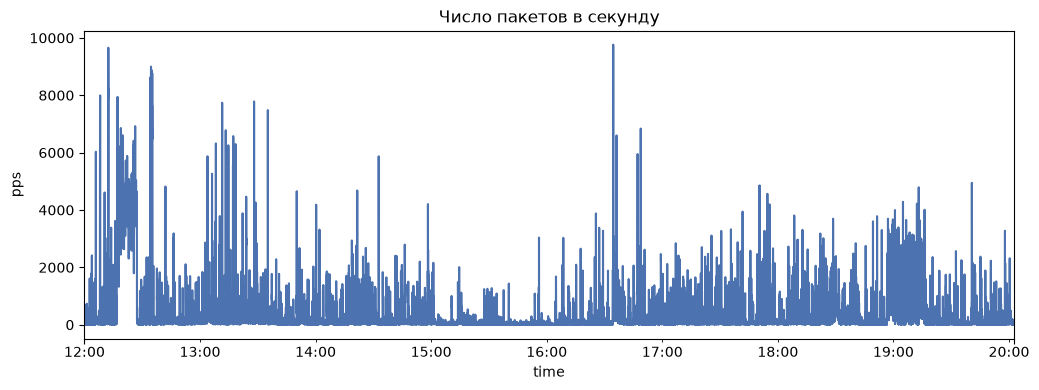

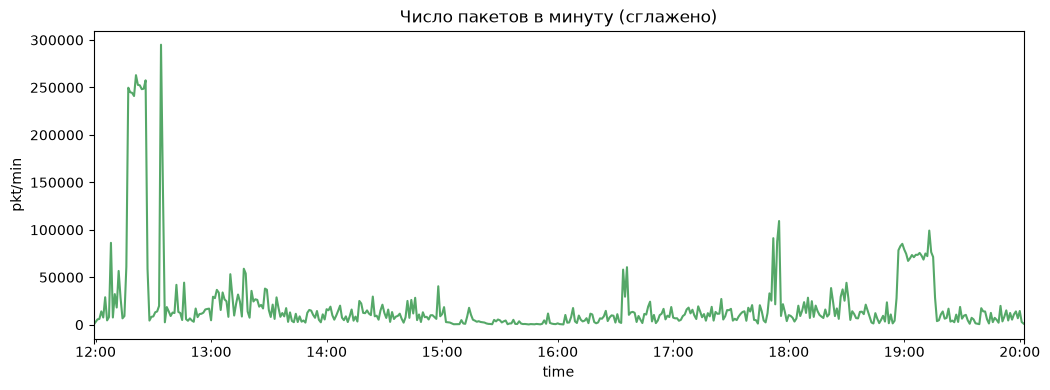

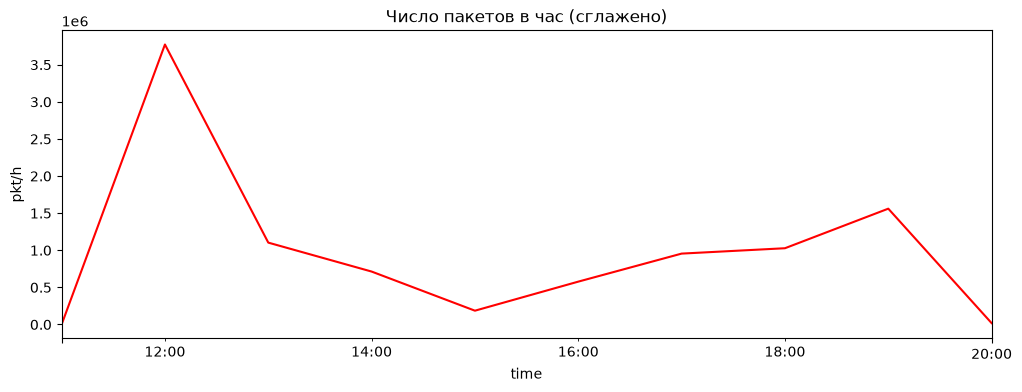

,unique_dst_ips
src_ip,
192.168.10.15,2274
192.168.10.5,2078
192.168.10.14,1963
192.168.10.9,1952
192.168.10.12,1814
192.168.10.16,1680
192.168.10.19,1679
192.168.10.8,1630
192.168.10.17,1535


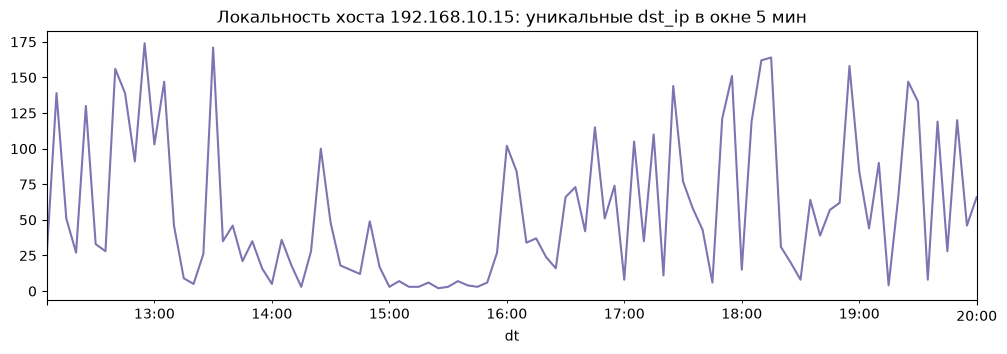

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

# Создаем временной индекс
ts_series = pd.Series(1, index=pd.to_datetime(df["time"], unit="s", utc=True))

# 1. Пакеты в секунду
by_sec = ts_series.resample("1s").sum()
fig, ax = plt.subplots(figsize=(12, 4))
by_sec.plot(ax=ax, color="#4C72B0")
ax.set_title("Число пакетов в секунду")
ax.set_ylabel("pps")
plt.show()

# 2. Пакеты в минуту
by_min = ts_series.resample("1min").sum()
fig, ax = plt.subplots(figsize=(12, 4))
by_min.plot(ax=ax, color="#55A868")
ax.set_title("Число пакетов в минуту (сглажено)")
ax.set_ylabel("pkt/min")
plt.show()

# 3. Пакеты в час
by_hour = ts_series.resample("1h").sum()
fig, ax = plt.subplots(figsize=(12, 4))
by_hour.plot(ax=ax, color="red")
ax.set_title("Число пакетов в час (сглажено)")
ax.set_ylabel("pkt/h")
plt.show()


# Подготовка данных для локальности
p = df.dropna(subset=["src_ip", "dst_ip"]).copy()
p["dt"] = pd.to_datetime(p["time"], unit="s", utc=True)

# Преобразуем Series в DataFrame, чтобы получить красивую табличку
locality_table = p.groupby('src_ip')['dst_ip'].nunique().sort_values(ascending=False).to_frame(name='unique_dst_ips')

# Выводим табличку
display(locality_table.head(10))

top_src = p.groupby('src_ip')['dst_ip'].nunique().idxmax()

sub = p[p["src_ip"] == top_src].set_index("dt").sort_index()


# Количество уникальных dst_ip в окне 5 минут
uniq_rolling = (sub["dst_ip"].resample("5min").nunique())

fig, ax = plt.subplots(figsize=(12, 3.5))
uniq_rolling.plot(ax=ax, color="#8172B2")
ax.set_title(f"Локальность хоста {top_src}: уникальные dst_ip в окне 5 мин")
plt.show()

## Граф

Агрегация данных для графа...
Узлов (уникальных IP): 8,329; Рёбер (связей): 35,297

Топ-10 узлов по степени посредничества (Betweenness):


,degree_flows,betweenness
192.168.10.12,492297,0.359594
192.168.10.5,593934,0.296699
173.194.207.127,6,0.247800
192.168.10.15,3652151,0.194488
192.168.10.14,575910,0.194016
192.168.10.8,457738,0.188182
192.168.10.25,454799,0.187330
192.168.10.9,537887,0.186820
192.168.10.19,423822,0.183133
103.224.182.245,10,0.175307


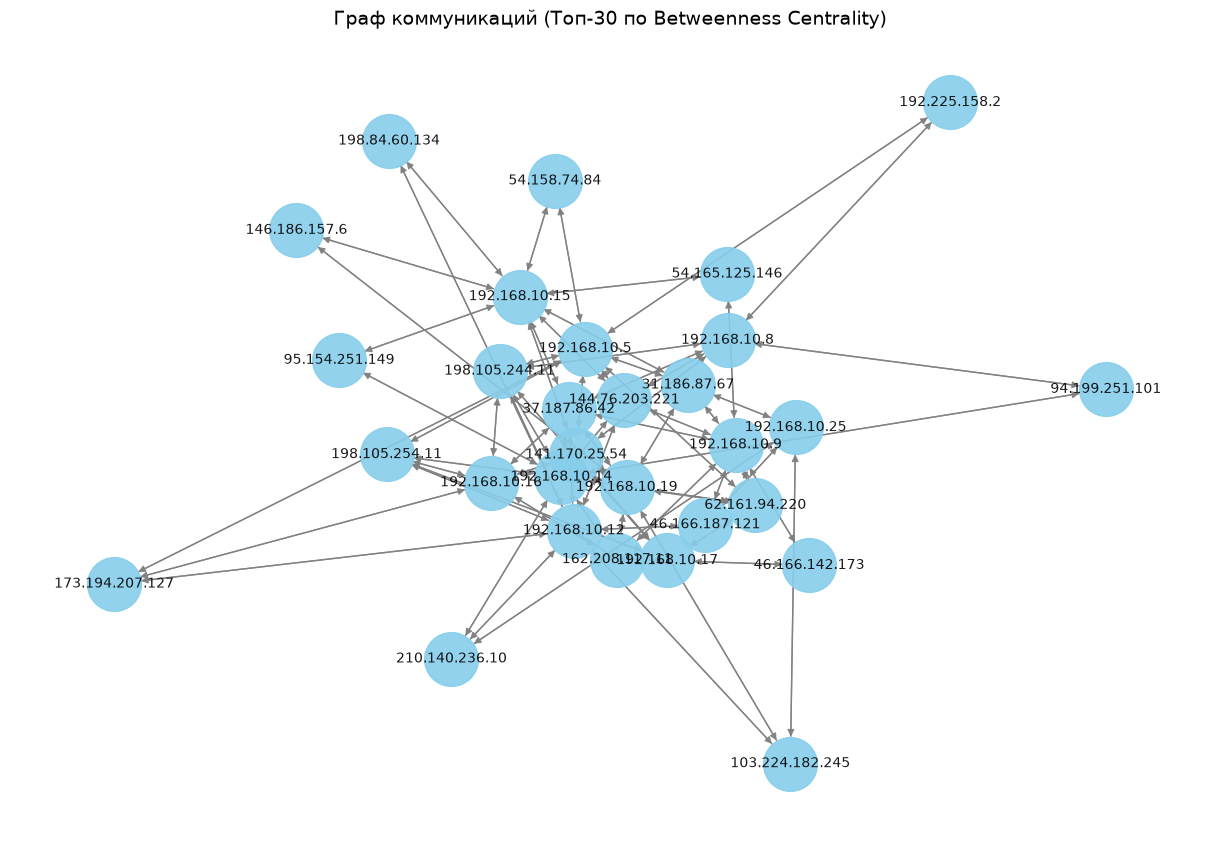

In [7]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

print("Агрегация данных для графа...")
# 1. Быстрая агрегация рёбер графа (суммируем байты и считаем потоки между IP)
edges_df = df.groupby(['src_ip', 'dst_ip']).agg(
    weight=('length', 'sum'),
    flows=('time', 'size')
).reset_index()

# 2. Создание направленного графа
G = nx.from_pandas_edgelist(
    edges_df, source='src_ip', target='dst_ip',
    edge_attr=['weight', 'flows'], create_using=nx.DiGraph()
)

print(f"Узлов (уникальных IP): {G.number_of_nodes():,}; Рёбер (связей): {G.number_of_edges():,}")

# 3. Расчет центральностей
# Степень вершины (взвешенная по количеству потоков)
deg = pd.Series(dict(G.degree(weight="flows")), name="degree_flows")
# Посредничество (betweenness). Для больших графов используем аппроксимацию k=200 для скорости
btw = pd.Series(
    nx.betweenness_centrality(G, k=min(200, G.number_of_nodes()), weight="flows", seed=1),
    name="betweenness"
)
central = pd.concat([deg, btw], axis=1).sort_values("betweenness", ascending=False)

print("\nТоп-10 узлов по степени посредничества (Betweenness):")
display(central.head(10))

# 4. Визуализация "ядра" графа (Топ-30 самых центральных узлов)
top_nodes = central.head(30).index.tolist()
H = G.subgraph(top_nodes)

plt.figure(figsize=(12, 8))
# spring_layout лучше подходит для визуализации реальных сетей, чем planar
pos = nx.spring_layout(H, k=0.8, seed=42) 

nx.draw(
    H, pos, 
    with_labels=True, 
    node_color='skyblue', 
    node_size=1500, 
    font_size=10, 
    edge_color='gray', 
    arrows=True,
    alpha=0.9
)
plt.title("Граф коммуникаций (Топ-30 по Betweenness Centrality)", fontsize=14)
plt.show()

Узлов: 8,329; Рёбер: 35,297

Топ-10 узлов по betweenness:


,degree_flows,in_flows,out_flows,betweenness
192.168.10.5,43266,21591,21675,0.200445
192.168.10.15,44495,22213,22282,0.199883
192.168.10.9,39569,19738,19831,0.198251
192.168.10.14,37487,18715,18772,0.193992
192.168.10.17,31859,15911,15948,0.187521
192.168.10.12,48889,24420,24469,0.177832
192.168.10.19,38118,19044,19074,0.168030
192.168.10.25,14076,7030,7046,0.152233
192.168.10.16,33824,16891,16933,0.135896
192.168.10.8,34443,17155,17288,0.127668



Топ-10 узлов по degree_flows:


,degree_flows,in_flows,out_flows,betweenness
192.168.10.50,423057,211627,211430,0.000509
172.16.0.1,409918,204758,205160,0.000057
192.168.10.3,206588,103274,103314,0.003029
192.168.10.12,48889,24420,24469,0.177832
192.168.10.15,44495,22213,22282,0.199883
192.168.10.5,43266,21591,21675,0.200445
192.168.10.9,39569,19738,19831,0.198251
192.168.10.19,38118,19044,19074,0.168030
192.168.10.14,37487,18715,18772,0.193992
192.168.10.8,34443,17155,17288,0.127668



Топ-10 узлов по closeness_top500:


,degree_flows,in_flows,out_flows,betweenness,closeness_top500
192.168.10.15,44495,22213,22282,0.199883,0.644468
192.168.10.14,37487,18715,18772,0.193992,0.642788
192.168.10.9,39569,19738,19831,0.198251,0.625657
192.168.10.12,48889,24420,24469,0.177832,0.616273
192.168.10.5,43266,21591,21675,0.200445,0.612445
192.168.10.19,38118,19044,19074,0.168030,0.601242
192.168.10.16,33824,16891,16933,0.135896,0.595432
192.168.10.8,34443,17155,17288,0.127668,0.575284
192.168.10.17,31859,15911,15948,0.187521,0.571947
192.168.10.3,206588,103274,103314,0.003029,0.505660


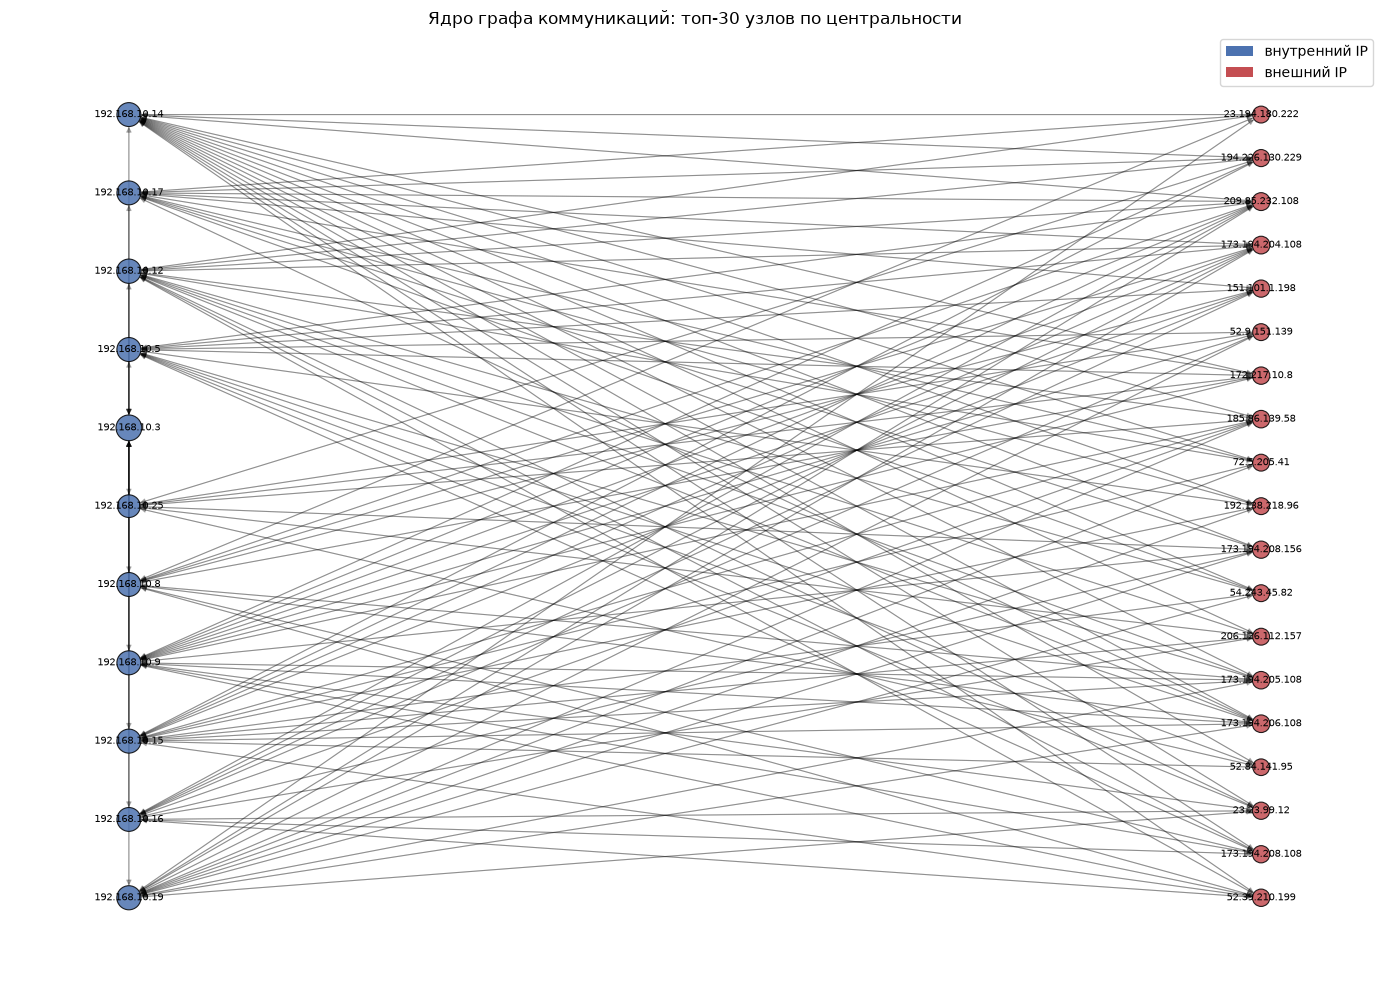

In [ ]:
# 1. Создаем ребра (если flows еще не создан - делаем fallback)
if "flows" not in globals():
    flows = (
        df.groupby(["src_ip", "dst_ip", "sport", "dport", "protocol"], as_index=False)
          .agg(
              start_time=("time", "min"),
              packet_count=("length", "count"),
              total_bytes=("length", "sum"),
          )
    )

edge_df = (
    flows.groupby(["src_ip", "dst_ip"], as_index=False)
         .agg(
             weight=("total_bytes", "sum"),
             flows=("total_bytes", "size"),
         )
)

G = nx.from_pandas_edgelist(
    edge_df,
    source="src_ip",
    target="dst_ip",
    edge_attr=["weight", "flows"],
    create_using=nx.DiGraph(),
)

print(f"Узлов: {G.number_of_nodes():,}; Рёбер: {G.number_of_edges():,}")

# 2. Считаем центральности
deg = pd.Series(dict(G.degree(weight="flows")), name="degree_flows")
in_deg = pd.Series(dict(G.in_degree(weight="flows")), name="in_flows")
out_deg = pd.Series(dict(G.out_degree(weight="flows")), name="out_flows")

# Для betweenness используем k=200 для ускорения на больших графах
btw = pd.Series(
    nx.betweenness_centrality(
        G, k=min(200, G.number_of_nodes()), weight="flows", seed=1
    ),
    name="betweenness",
)

central = (
    pd.concat([deg, in_deg, out_deg, btw], axis=1)
      .fillna(0)
      .sort_values(["betweenness", "degree_flows"], ascending=False)
)

print("\nТоп-10 узлов по betweenness:")
display(central.head(10))

print("\nТоп-10 узлов по degree_flows:")
display(central.sort_values("degree_flows", ascending=False).head(10))

# 3. Closeness на подграфе топ-500 (на полном графе считать слишком долго)
top500 = central.sort_values("degree_flows", ascending=False).head(500).index
close_series = pd.Series(
    nx.closeness_centrality(G.subgraph(top500), wf_improved=True),
    name="closeness_top500",
)
central = central.join(close_series)

print("\nТоп-10 узлов по closeness_top500:")
display(central.sort_values("closeness_top500", ascending=False).head(10))

# ============================================================
# Визуализация «ядра» графа: топ-30 узлов
# ============================================================

def _is_internal_ip(ip: str) -> bool:
    try:
        return ipaddress.ip_address(ip).is_private
    except ValueError:
        return False

top_nodes = central.head(30).index.tolist()
H = G.subgraph(top_nodes)

# Разделяем узлы на внутренние и внешние
internal_nodes = [n for n in H.nodes() if _is_internal_ip(n)]
external_nodes = [n for n in H.nodes() if not _is_internal_ip(n)]

# Используем двудольный (bipartite) layout: 
# внутренние узлы слева, внешние справа. 
# Это избавит от эффекта "схлопывания" в один шар.
pos = nx.bipartite_layout(H, internal_nodes, align='vertical', scale=2.0)

# Цвета узлов: синие - внутренние, красные - внешние
node_colors = ["#4C72B0" if _is_internal_ip(n) else "#C44E52" for n in H.nodes()]

# Уменьшаем размеры узлов, чтобы подписи не перекрывались
node_sizes = [100 + 20 * np.log1p(H.degree(n, weight="flows")) for n in H.nodes()]

fig, ax = plt.subplots(figsize=(14, 10))

# Рисуем рёбра (передаем node_size, чтобы стрелки не залезали под кружки)
nx.draw_networkx_edges(
    H, pos, ax=ax, alpha=0.25, arrows=True, arrowsize=8, width=0.8,
    node_size=node_sizes,
)

# Рисуем узлы
nx.draw_networkx_nodes(
    H, pos, ax=ax, node_size=node_sizes, node_color=node_colors,
    alpha=0.85, linewidths=0.8, edgecolors="black",
)

# Подписи
nx.draw_networkx_labels(H, pos, ax=ax, font_size=7)

# Легенда
legend_elements = [
    Patch(facecolor="#4C72B0", label="внутренний IP"),
    Patch(facecolor="#C44E52", label="внешний IP"),
]
ax.legend(handles=legend_elements, loc="upper right")
ax.set_title("Ядро графа коммуникаций: топ-30 узлов по центральности")
ax.axis("off")
plt.tight_layout()
plt.show()

In [31]:
# ============================================================
# Блок 6. Контент-анализ, идентификация приложений, граф
# ============================================================
import re
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scapy.all import PcapReader, IP, TCP, Raw

print("1. Извлечение HTTP-заголовков...")
# Простой извлекатель HTTP-заголовков из Raw-слоя
RE_HTTP_REQ  = re.compile(rb"^(?P<method>GET|POST|PUT|DELETE|HEAD|OPTIONS|PATCH)\s+(?P<uri>\S+)\s+HTTP/1\.[01]", re.M)
RE_HTTP_HDR  = re.compile(rb"^(?P<name>[A-Za-z\-]+):\s*(?P<val>[^\r\n]+)", re.M)
RE_HTTP_RESP = re.compile(rb"^HTTP/1\.[01]\s+(?P<code>\d{3})", re.M)

PCAP_PATH = "Friday-WorkingHours.pcap"
http_rows = []

# Ограничиваем чтение 500к пакетов для скорости, чтобы не ждать вечность на 9 ГБ
with PcapReader(PCAP_PATH) as rdr:
    for i, pkt in enumerate(rdr):
        if i > 500000: break 
        if pkt.haslayer(Raw) and pkt.haslayer(TCP):
            raw = bytes(pkt[Raw].load)[:2000]
            if b"HTTP/1." not in raw:
                continue
            row = {"src_ip": pkt[IP].src if pkt.haslayer(IP) else None,
                   "dst_ip": pkt[IP].dst if pkt.haslayer(IP) else None,
                   "method": None, "host": None, "code": None}
            
            m = RE_HTTP_REQ.search(raw)
            if m: row["method"] = m.group("method").decode()
            m = RE_HTTP_RESP.search(raw)
            if m: row["code"] = int(m.group("code"))
            for hm in RE_HTTP_HDR.finditer(raw):
                name = hm.group("name").decode().lower()
                val  = hm.group("val").decode(errors="ignore")
                if name == "host": row["host"] = val
            
            if row["host"] or row["method"] or row["code"]:
                http_rows.append(row)

http = pd.DataFrame(http_rows)
print(f"HTTP-наблюдений: {len(http):,}")
if len(http) > 0:
    print("\nТоп HTTP-кодов:")
    display(http['code'].value_counts().head())
    print("\nТоп HTTP-Hosts:")
    display(http['host'].value_counts().head(5))


print("\n2. Извлечение TLS SNI (без модуля TLS Scapy)...")
# Ручной поиск SNI в байтах (обходит баг Python 3.14 + Scapy)
RE_SNI = re.compile(rb'\x00\x00' + rb'.' * 18 + rb'([a-zA-Z0-9.-]+\.[a-zA-Z]{2,})', re.DOTALL)

sni_rows = []
with PcapReader(PCAP_PATH) as reader:
    for i, pkt in enumerate(reader):
        if i > 500000: break
        if pkt.haslayer(TCP) and pkt.haslayer(Raw):
            tcp = pkt[TCP]
            if tcp.dport == 443 or tcp.sport == 443:
                raw = bytes(pkt[Raw].load)
                m = RE_SNI.search(raw[:1000])
                if m:
                    sni = m.group(1).decode('utf-8', errors='ignore')
                    sni_rows.append({"src": pkt[IP].src, "dst": pkt[IP].dst, "sni": sni})

sni = pd.DataFrame(sni_rows)
print(f"SNI-наблюдений: {len(sni):,}")
if len(sni) > 0:
    print("\nТоп TLS SNI (домены):")
    display(sni['sni'].value_counts().head(5))


print("\n3. Идентификация приложений (по портам)...")
app_map = {80: "HTTP", 443: "HTTPS", 53: "DNS", 22: "SSH", 139: "NetBIOS", 445: "SMB", 8080: "HTTP-Alt"}
if 'df' in globals():
    app_counts = df[df['dport'].isin(app_map.keys())]['dport'].map(app_map).value_counts()
    display(app_counts.head(5))


print("\n4. Построение графа коммуникаций...")
# Если flows не создан, создаем его
if "flows" not in globals():
    flows = df.groupby(["src_ip", "dst_ip", "sport", "dport", "protocol"], as_index=False).agg(
        start_time=("time", "min"), packet_count=("length", "count"), total_bytes=("length", "sum"))

# Строим граф IP -> IP
G = nx.DiGraph()
for _, row in flows.iterrows():
    w = int(row["total_bytes"])
    if G.has_edge(row["src_ip"], row["dst_ip"]):
        G[row["src_ip"]][row["dst_ip"]]["weight"] += w
        G[row["src_ip"]][row["dst_ip"]]["flows"]  += 1
    else:
        G.add_edge(row["src_ip"], row["dst_ip"], weight=w, flows=1)

print(f"Узлов: {G.number_of_nodes():,}; Рёбер: {G.number_of_edges():,}")

# Центральности
deg = pd.Series(dict(G.degree(weight="flows")), name="degree_flows")
btw = pd.Series(nx.betweenness_centrality(G, k=min(100, G.number_of_nodes()), weight="flows", seed=1), name="betweenness")
central = pd.concat([deg, btw], axis=1).sort_values("degree_flows", ascending=False)

print("\nТоп-10 узлов по degree_flows (Хабы):")
display(central.head(10))

1. Извлечение HTTP-заголовков...
HTTP-наблюдений: 3,871

Топ HTTP-кодов:


code
200.0    1537
206.0     133
302.0     111
304.0     107
404.0      33
Name: count, dtype: int64


Топ HTTP-Hosts:


host
lvlt.vscdns.com          200
cdn1.vscdns.com          191
ocsp.digicert.com        177
clients1.google.com      100
ca.archive.ubuntu.com     98
Name: count, dtype: int64


2. Извлечение TLS SNI (без модуля TLS Scapy)...
SNI-наблюдений: 1,113

Топ TLS SNI (домены):


sni
oudfront.cdn.mozilla.net      32
te.microsoft.com              25
.telemetry.mozilla.org        24
heck-bg.addons.mozilla.org    24
book.com                      20
Name: count, dtype: int64


3. Идентификация приложений (по портам)...


dport
HTTP        2627613
HTTPS       1428954
DNS          345401
SSH           41442
HTTP-Alt       9416
Name: count, dtype: int64


4. Построение графа коммуникаций...
Узлов: 8,329; Рёбер: 35,297

Топ-10 узлов по degree_flows (Хабы):


,degree_flows,betweenness
192.168.10.50,423057,0.000514
172.16.0.1,409918,0.000114
192.168.10.3,206588,0.003040
192.168.10.12,48889,0.150136
192.168.10.15,44495,0.194892
192.168.10.5,43266,0.198067
192.168.10.9,39569,0.220145
192.168.10.19,38118,0.182071
192.168.10.14,37487,0.185703
192.168.10.8,34443,0.136359


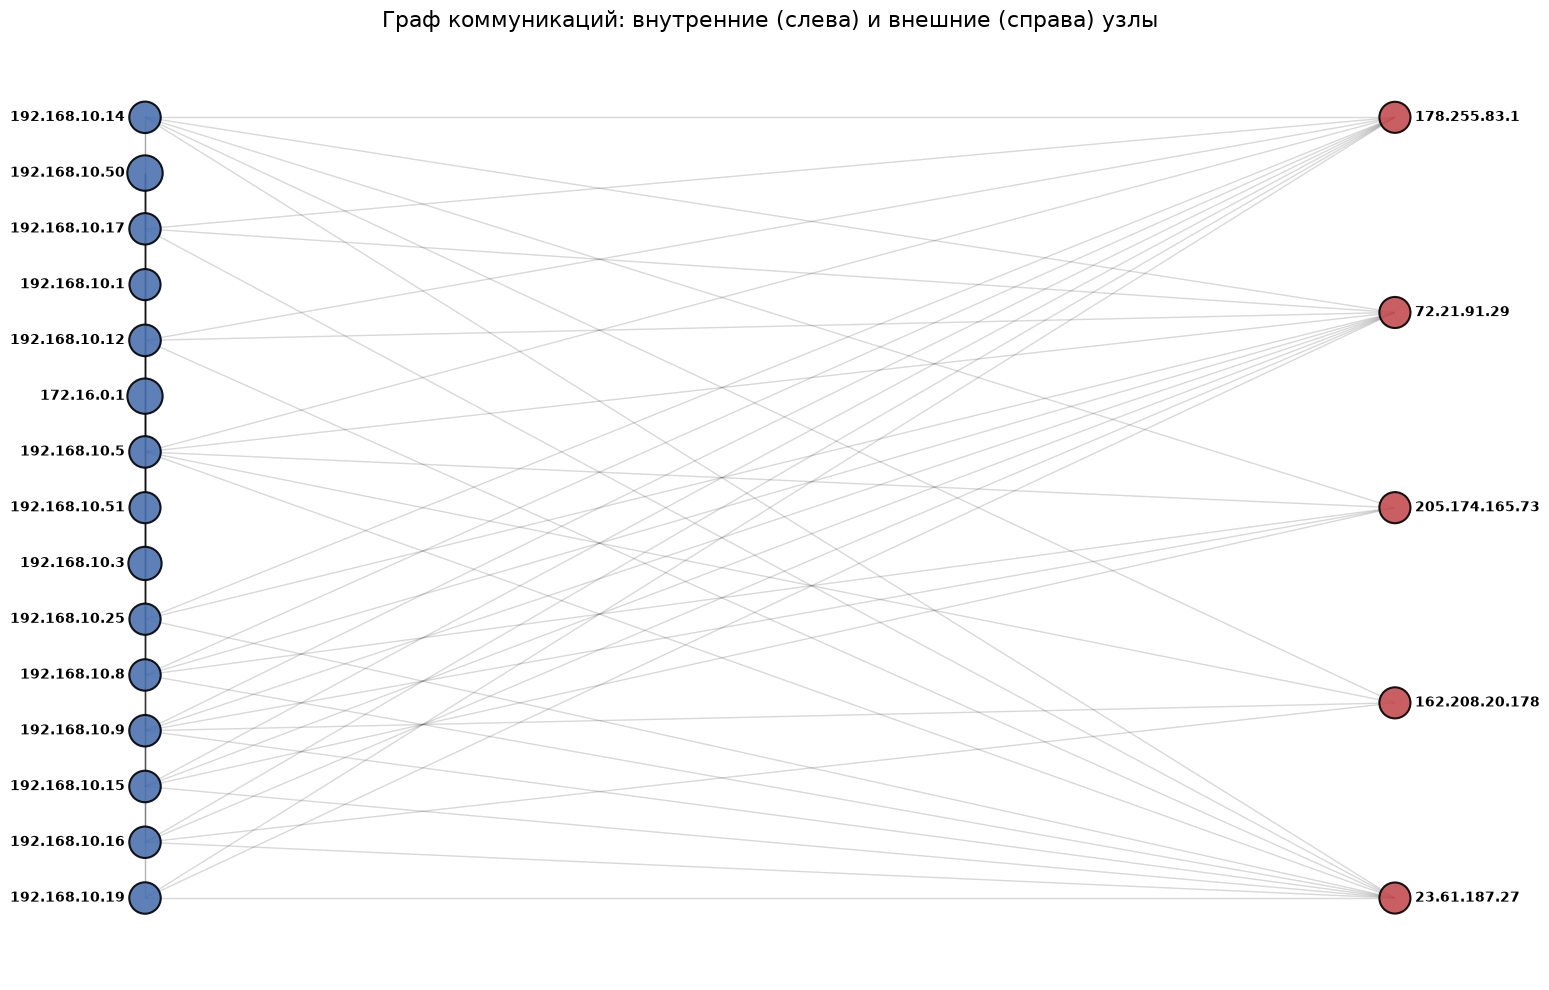

In [ ]:
# 1. Загружаем сохраненные данные
flows = pd.read_pickle("flows.pkl")
central = pd.read_pickle("central.pkl")

# 2. Строим граф
edge_df = flows.groupby(["src_ip", "dst_ip"], as_index=False).agg(
    weight=("total_bytes", "sum"),
    flows=("total_bytes", "size")
)
G = nx.from_pandas_edgelist(
    edge_df, source="src_ip", target="dst_ip", 
    edge_attr=["weight", "flows"], create_using=nx.DiGraph()
)

# 3. Берем ТОП-20 узлов
top_nodes = central.head(20).index.tolist()
H = G.subgraph(top_nodes)

# 4. Делим на внутренние и внешние
def is_internal(ip):
    return ip.startswith("192.168.") or ip.startswith("172.") or ip.startswith("10.")

internal_nodes = [n for n in H.nodes() if is_internal(n)]
external_nodes = [n for n in H.nodes() if not is_internal(n)]

# --- Делаем двудольный макет ---
# Он насильно ставит одних слева, других справа. Это убирает кашу.
pos = nx.bipartite_layout(H, internal_nodes, align='vertical', scale=2.5)

# Чуть-чуть растаскиваем узлы по вертикали, если их слишком много в одной колонке
pos = {n: (x * 1.5, y) for n, (x, y) in pos.items()}

plt.figure(figsize=(16, 10)) # Огромный холст

# 5. Рисуем РЕБРА (без стрелок, очень прозрачные, чтобы не загораживали узлы)
nx.draw_networkx_edges(
    H, pos, alpha=0.08, edge_color="black", width=1, arrows=False
)

# 6. Рисуем УЗЛЫ
node_colors = ["#4C72B0" if is_internal(n) else "#C44E52" for n in H.nodes()]
# Размер зависит от количества потоков (degree_flows), но не слишком огромный
node_sizes = [500 + 150 * (central.loc[n, 'degree_flows'] / central['degree_flows'].max()) for n in H.nodes()]

nx.draw_networkx_nodes(
    H, pos, node_size=node_sizes, node_color=node_colors, 
    edgecolors="black", linewidths=1.5, alpha=0.9
)

# 7. Рисуем ПОДПИСИ (выравниваем: слева — влево, справа — вправо)
for node, (x, y) in pos.items():
    ha = 'right' if is_internal(node) else 'left'
    offset = -0.08 if is_internal(node) else 0.08
    plt.text(
        x + offset, y, node, 
        fontsize=10, fontweight='bold', 
        ha=ha, va='center',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1)
    )

plt.title("Граф коммуникаций: внутренние (слева) и внешние (справа) узлы", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()

Внутренний граф (Топ-15): 15 узлов, 59 связей


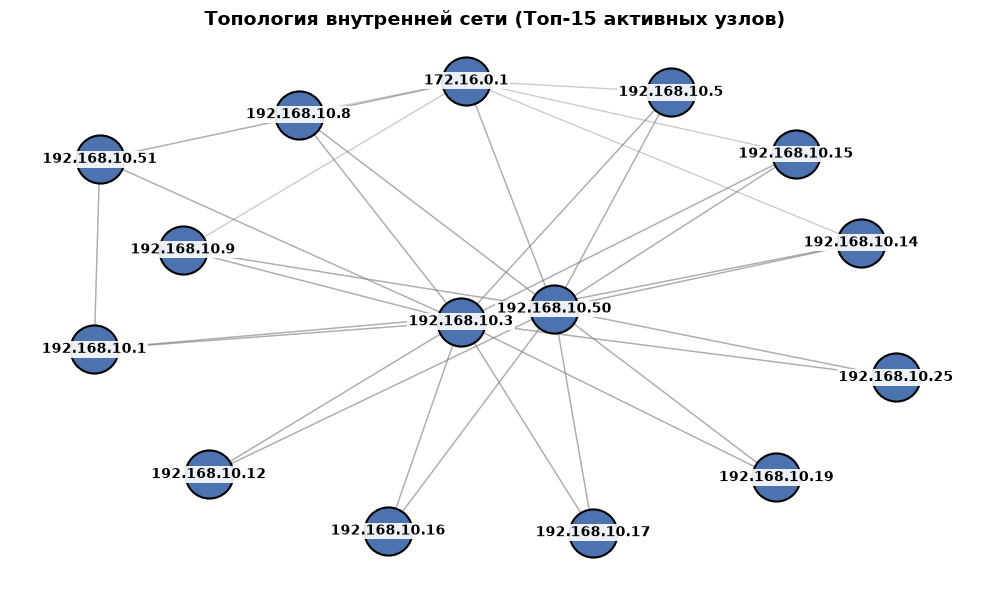

In [9]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 1. Загружаем данные
flows = pd.read_pickle("flows.pkl")

def is_internal(ip):
    return ip.startswith("192.168.") or ip.startswith("172.") or ip.startswith("10.")

# 2. Отфильтровываем только внутренние связи
df_internal = flows[flows['src_ip'].apply(is_internal) & flows['dst_ip'].apply(is_internal)]

# --- ГЛАВНОЕ ИСПРАВЛЕНИЕ ---
# Находим Топ-15 самых активных внутренних узлов по объему байт
top_internal_ips = (
    pd.concat([df_internal['src_ip'], df_internal['dst_ip']])
    .value_counts()
    .nlargest(15)
    .index
)

# Оставляем только те потоки, где оба конца входят в Топ-15
df_internal_filtered = df_internal[
    (df_internal['src_ip'].isin(top_internal_ips)) & 
    (df_internal['dst_ip'].isin(top_internal_ips))
]

# 3. Строим граф
G_int = nx.from_pandas_edgelist(
    df_internal_filtered, source="src_ip", target="dst_ip", 
    edge_attr=["total_bytes"], create_using=nx.DiGraph()
)

print(f"Внутренний граф (Топ-15): {G_int.number_of_nodes()} узлов, {G_int.number_of_edges()} связей")

# 4. Рисуем
plt.figure(figsize=(10, 6))
pos = nx.kamada_kawai_layout(G_int) 

nx.draw_networkx_edges(G_int, pos, alpha=0.4, arrows=True, arrowsize=15, edge_color="gray")
nx.draw_networkx_nodes(G_int, pos, node_size=1200, node_color="#4C72B0", edgecolors="black", linewidths=1.5)

nx.draw_networkx_labels(
    G_int, pos, font_size=10, font_weight="bold",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.9, pad=1)
)

plt.title("Топология внутренней сети (Топ-15 активных узлов)", fontsize=14, fontweight='bold')
plt.axis("off")
plt.tight_layout()
plt.show()

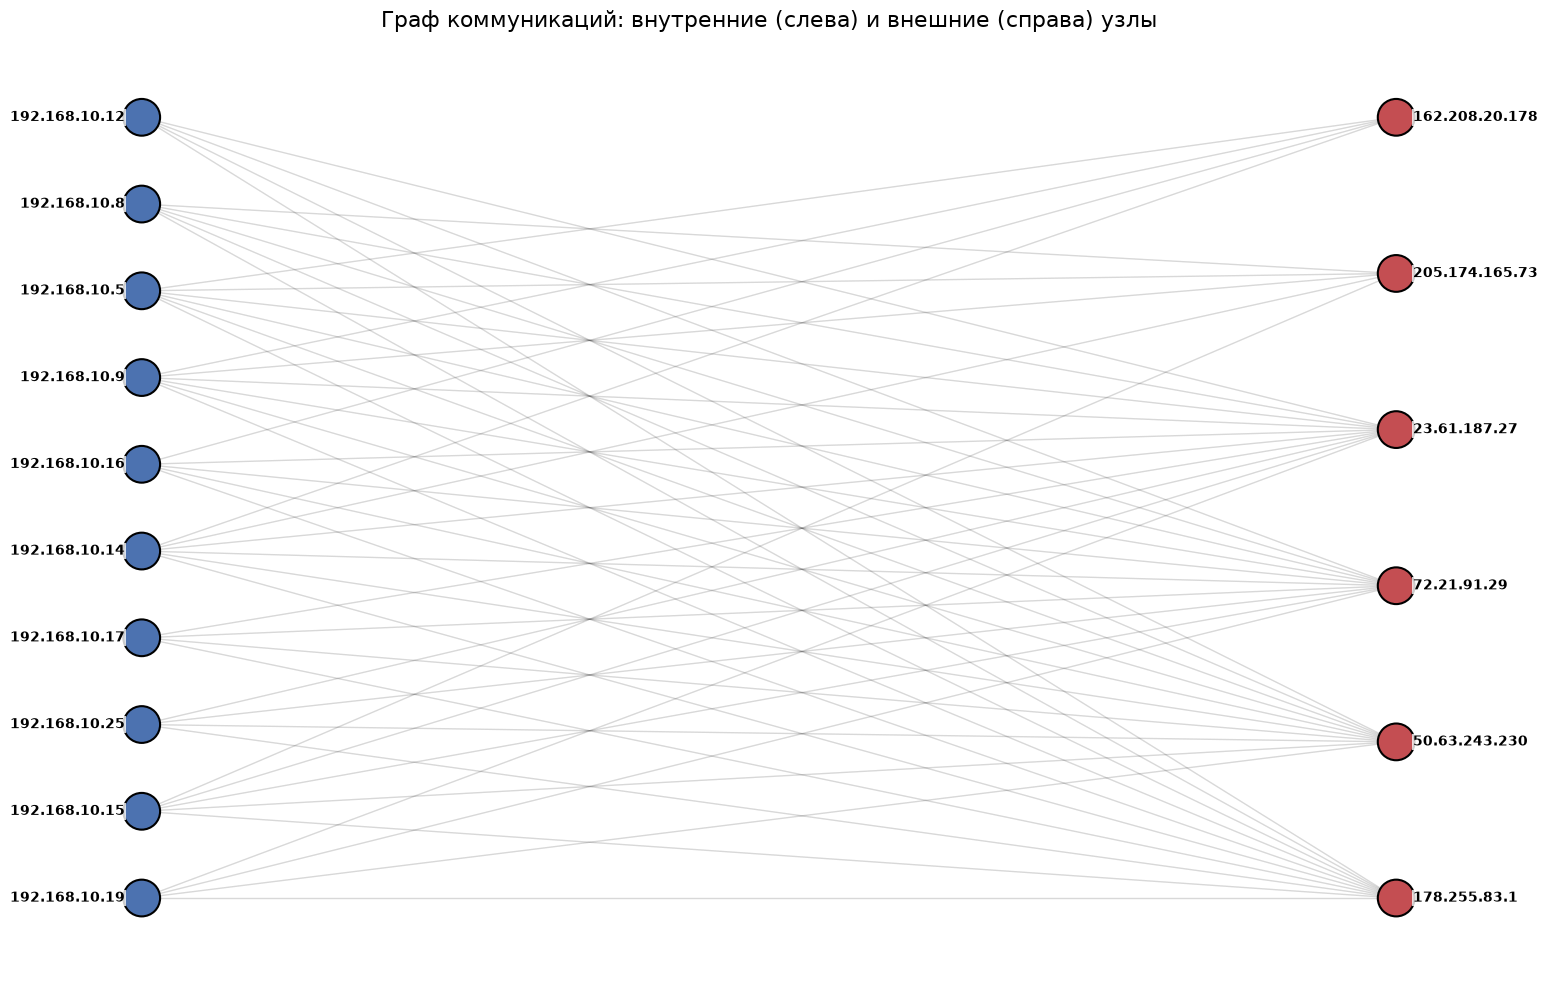

In [10]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 1. Загружаем данные
flows = pd.read_pickle("flows.pkl")

def is_internal(ip):
    return ip.startswith("192.168.") or ip.startswith("172.") or ip.startswith("10.")

# 2. Берем Топ-15 внутренних и Топ-6 внешних узлов по объему трафика
top_internal = flows[flows['src_ip'].apply(is_internal)]['src_ip'].value_counts().nlargest(15).index.tolist()
top_external = flows[~flows['dst_ip'].apply(is_internal)]['dst_ip'].value_counts().nlargest(6).index.tolist()

# Оставляем только связи между этими узлами
df_filtered = flows[
    (flows['src_ip'].isin(top_internal) & flows['dst_ip'].isin(top_external)) |
    (flows['src_ip'].isin(top_external) & flows['dst_ip'].isin(top_internal))
]

# 3. Строим граф
G = nx.from_pandas_edgelist(
    df_filtered, source="src_ip", target="dst_ip", 
    create_using=nx.DiGraph()
)

# 4. Рисуем двудольный макет
plt.figure(figsize=(16, 10))

# Разделяем для макета
internal_nodes = [n for n in G.nodes() if is_internal(n)]
external_nodes = [n for n in G.nodes() if not is_internal(n)]

pos = nx.bipartite_layout(G, internal_nodes, align='vertical', scale=2.5)
pos = {n: (x * 1.5, y) for n, (x, y) in pos.items()}

# Цвета
node_colors = ["#4C72B0" if is_internal(n) else "#C44E52" for n in G.nodes()]

# Рисуем связи (очень прозрачные, без стрелок)
nx.draw_networkx_edges(G, pos, alpha=0.08, edge_color="black", width=1, arrows=False)

# Рисуем узлы
nx.draw_networkx_nodes(G, pos, node_size=700, node_color=node_colors, edgecolors="black", linewidths=1.5)

# Подписи с белым фоном и выравниванием
for node, (x, y) in pos.items():
    ha = 'right' if is_internal(node) else 'left'
    offset = -0.08 if is_internal(node) else 0.08
    plt.text(x + offset, y, node, fontsize=10, fontweight='bold', 
             ha=ha, va='center',
             bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1))

plt.title("Граф коммуникаций: внутренние (слева) и внешние (справа) узлы", fontsize=16)
plt.axis("off")
plt.tight_layout()
plt.show()